# Predicting ICU Length of Stay in Acute Traumatic Cervical Spinal Cord Injury
### MIMIC-IV (primary analysis) and MIMIC-III CareVue (separate secondary analysis)


## Research questions
1. Using only information available in the first 24 hours of an ICU stay, can a statistical model predict ICU length of stay (LOS) for adults with an acute cervical spinal cord injury (ICD-9 806.0x / ICD-10 S14.1xxA)?
2. Does that model predict LOS better than (a) a "predict the typical LOS for everybody" baseline and (b) a severity-score baseline (an **APACHE-II approximation**; not APACHE-IV, see notes)?
3. Do conclusions replicate in a second, older data source (MIMIC-III CareVue era), analysed **separately**?

## Design decisions (and why)
| Decision | Reason |
|---|---|
| MIMIC-IV is the primary analysis; MIMIC-III CareVue is analysed separately and **never pooled** | Patient identities cannot be matched across the two datasets (dates are shifted independently), so pooling or calling MIMIC-III "external validation" cannot be justified |
| One ICU stay per hospital admission (the first) | Later stays are readmissions whose first 24h look different and may not be linked to the injury |
| Stays shorter than 24h are excluded | A "first-24-hour" feature set is cut short by the outcome for these stays; a prediction made at hour 24 only applies to patients still in the ICU |
| Cross-validation is **grouped by patient** and repeated; imputation/scaling live inside the CV pipeline | Prevents patient overlap and imputer/scaler leakage between folds |
| `hospital_expire_flag`, discharge info and any post-24h data are never predictors | Not known at hour 24 |
| Race and marital status are not used | Different vocabularies across datasets, too many categories for ~150 rows, little clinical justification |
| Labs are joined to stays through `hadm_id` **with a per-stay time window** | An admission can contain more than one ICU stay; joining labs by admission alone would hand them to the wrong stay |
| Every key choice (24h window, minimum stay, the one 99-day stay) is re-tested automatically in Step 9 | Shows how much the conclusions depend on our assumptions, with no manual re-running |

**How to run:** set the two data paths in Step 0, then Run All. The slow part is scanning the large MIMIC event files (once per dataset). Every sensitivity setting is then computed from that single extraction, so nothing has to be re-run by hand.

## Step 0 — Setup and parameters

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 1000)

# --- Paths (override with environment variables if needed) ---
MIMIC_IV_BASE = os.environ.get(
    'MIMIC_IV_BASE',
    r"C:\Users\7PSYCHOPATH\Documents\To be done\Project 1 - Predicting ICU\mimic-iv-2.2")
MIMIC_III_BASE = os.environ.get(
    'MIMIC_III_BASE',
    r"C:\Users\7PSYCHOPATH\Documents\To be done\Project 1 - Predicting ICU\mimic-iii-clinical-database-1.4")
IV_HOSP = os.path.join(MIMIC_IV_BASE, 'hosp')
IV_ICU = os.path.join(MIMIC_IV_BASE, 'icu')

# --- Analysis parameters (these are assumptions; Step 9 re-tests the important ones automatically) ---
LAB_PRE_HOURS = 6        # labs drawn up to this many hours BEFORE ICU admission are also allowed
MAX_WINDOW = 48          # data are extracted once for up to this many hours; each setting below uses its own (shorter or equal) window
RANDOM_STATE = 42
N_SPLITS = 5             # grouped CV folds
N_REPEATS = 10           # repeats of grouped CV for the PRIMARY analysis (different patient shuffles)
N_BOOT = 1000            # patient-level bootstrap resamples for the PRIMARY analysis
N_REPEATS_SENS = 3       # lighter settings for the sensitivity runs (keeps total run time reasonable)
N_BOOT_SENS = 300
CLIP_PREDICTIONS = True  # limit predictions to the range of LOS values seen in the training fold (stops a few absurd extrapolations)
CHUNK = 500_000          # rows per chunk when scanning the big event tables
OUT_DIR = os.environ.get('OUT_DIR', 'results_FINAL')
os.makedirs(OUT_DIR, exist_ok=True)

# Each setting is one full analysis. The FIRST is the primary analysis; the others test whether our choices matter.
#   window  = hours of ICU data used as predictors        min_los = stays shorter than this many HOURS are excluded
#   max_los = stays longer than this many DAYS are excluded (None = keep everyone)
SETTINGS = {
    'Primary (24h window, min stay 24h)': dict(window=24, min_los=24, max_los=None),
    'Keep short stays (24h window, no minimum stay)': dict(window=24, min_los=0, max_los=None),
    'Shorter window (12h window, min stay 12h)': dict(window=12, min_los=12, max_los=None),
    'Longer window (48h window, min stay 48h)': dict(window=48, min_los=48, max_los=None),
    'Drop the 99-day stay (24h window, min stay 24h)': dict(window=24, min_los=24, max_los=90),
}
PRIMARY = 'Primary (24h window, min stay 24h)'
assert max(cfg['window'] for cfg in SETTINGS.values()) <= MAX_WINDOW

# Columns that must NEVER be predictors
LEAKY = {'hospital_expire_flag', 'los_days', 'log_los', 'los', 'dod', 'dischtime', 'outtime',
         'discharge_location', 'apache_ii', 'apache_ii_no_gcs'}

# Physiologically plausible ranges (values outside are treated as recording errors)
PLAUSIBLE = {
    'heart_rate': (20, 250), 'sbp': (40, 300), 'dbp': (10, 200), 'mbp': (20, 250),
    'resp_rate': (4, 60), 'spo2': (50, 100), 'temp_c': (30, 43),
    'gcs_eye': (1, 4), 'gcs_motor': (1, 6), 'gcs_verbal': (1, 5), 'fio2': (21, 100),
    'creatinine': (0.1, 20), 'bun': (1, 200), 'wbc': (0.1, 100), 'hematocrit': (5, 65),
    'hemoglobin': (2, 22), 'platelets': (1, 1500), 'sodium': (100, 180), 'potassium': (1, 10),
    'chloride': (60, 150), 'bicarbonate': (5, 50), 'glucose': (10, 1000), 'lactate': (0.1, 30),
    'calcium': (3, 20), 'magnesium': (0.5, 10), 'ph': (6.8, 7.8), 'po2': (10, 600), 'pco2': (10, 150),
}
RANGE_LO = {k: v[0] for k, v in PLAUSIBLE.items()}
RANGE_HI = {k: v[1] for k, v in PLAUSIBLE.items()}

# Lab item ids (same ids in MIMIC-III and MIMIC-IV)
LAB_NAMES = {
    50912: 'creatinine', 51006: 'bun', 51301: 'wbc', 51221: 'hematocrit', 51222: 'hemoglobin',
    51265: 'platelets', 50983: 'sodium', 50971: 'potassium', 50902: 'chloride', 50882: 'bicarbonate',
    50931: 'glucose', 50813: 'lactate', 50893: 'calcium', 50960: 'magnesium',
    50820: 'ph', 50821: 'po2', 50818: 'pco2',
}
GAS_LABS = ['ph', 'po2', 'pco2']    # blood-gas values must come from ARTERIAL samples only

## Step 1 — APACHE-II scoring tables

**Important:** the brief names APACHE-IV. The APACHE-IV length-of-stay method and predictors were published, but reproducing the validated model requires APACHE-specific diagnosis mapping and model details that are not available in a ready-to-use form in these MIMIC tables. We therefore report an **APACHE-II approximation**, not APACHE-IV. Simplifications:
* Missing components score 0 in this implementation; this is a simplifying assumption, not a verified APACHE-II missing-data rule, and can bias scores downward. Missing FiO2 is treated as room air (21%).
* Oxygenation uses **arterial** blood gases only; each draw is scored with the FiO2 charted just before it, and the worst draw is kept.
* If there is no arterial pH, serum bicarbonate is used instead (as the original score allows).
* Chronic-health points are approximated using diagnosis codes assigned at discharge. They are not guaranteed to have been known by hour 24, so this is a retrospective comparator rather than a leakage-free bedside score.
* GCS points are unreliable in spinal cord injury (motor score reflects the cord; ventilated patients are charted verbal=1), so we also keep a **variant without GCS points**.

**How the tables work:** each variable has a list of cut-points (`edges`, ascending) and a list of points that has ONE more entry than `edges`. A value below the first edge gets `points[0]`, a value between edge 1 and edge 2 gets `points[1]`, and so on. Using cut-points (instead of closed ranges such as "36–38.4") avoids gaps for values like 35.95 °C.

In [2]:
APACHE_BANDS = {
    #  variable       edges (ascending)                       points (len(edges)+1)
    'temp_c':     ([30, 32, 34, 36, 38.5, 39, 41],           [4, 3, 2, 1, 0, 1, 3, 4]),
    'mbp':        ([50, 70, 110, 130, 160],                  [4, 2, 0, 2, 3, 4]),
    'heart_rate': ([40, 55, 70, 110, 140, 180],              [4, 3, 2, 0, 2, 3, 4]),
    'resp_rate':  ([6, 10, 12, 25, 35, 50],                  [4, 2, 1, 0, 1, 3, 4]),
    'ph':         ([7.15, 7.25, 7.33, 7.5, 7.6, 7.7],        [4, 3, 2, 0, 1, 3, 4]),
    'sodium':     ([111, 120, 130, 150, 155, 160, 180],      [4, 3, 2, 0, 1, 2, 3, 4]),
    'potassium':  ([2.5, 3, 3.5, 5.5, 6, 7],                 [4, 2, 1, 0, 1, 3, 4]),
    'creatinine': ([0.6, 1.5, 2, 3.5],                       [2, 0, 2, 3, 4]),
    'hematocrit': ([20, 30, 46, 50, 60],                     [4, 2, 0, 1, 2, 4]),
    'wbc':        ([1, 3, 15, 20, 40],                       [4, 2, 0, 1, 2, 4]),
}
HCO3_BAND = ([15, 18, 22, 32, 41, 52], [4, 3, 2, 0, 1, 3, 4])   # used only when no arterial pH exists
AGE_BAND = ([45, 55, 65, 75], [0, 2, 3, 5, 6])
PAO2_BAND = ([55, 61, 70.0001], [4, 3, 1, 0])                    # used when FiO2 < 50%
AADO2_BAND = ([200, 350, 500], [0, 2, 3, 4])                     # used when FiO2 >= 50%

# Quick self-check of the lookup logic (values between the old closed ranges used to fall through as 0 points)
lookup = lambda v, band: np.where(np.isnan(np.asarray(v, dtype=float)), 0,
                                   np.array(band[1])[np.searchsorted(band[0], np.asarray(v, dtype=float), side='right')])
assert lookup(35.95, APACHE_BANDS['temp_c']) == 1      # a gap-free lookup must give 1 point here
assert lookup(129.5, APACHE_BANDS['mbp']) == 2         # a gap-free lookup must give 1 point here
assert lookup(5.7, APACHE_BANDS['potassium']) == 1     # potassium 5.5-5.9 = 1 point
assert lookup(49.5, APACHE_BANDS['mbp']) == 4
assert lookup(40, PAO2_BAND) == 4 and lookup(80, PAO2_BAND) == 0
print('APACHE-II lookup self-checks passed')

# Chronic-health ICD prefixes (ICD-9, ICD-10). ICD-10 immune codes C81-C96.
CHRONIC_CODES = {
    'liver': (['5712', '5715', '5716', '5722', '5723'], ['K7030', 'K7031', 'K7460', 'K7469', 'K7290', 'K7291', 'K7210', 'K7211', 'K766', 'K717']),
    'heart': ([f'428{i}' for i in range(10)], [f'I50{i}' for i in range(10)]),
    'lung': (['496', '51883', '4160', '4161', '4168', '4169'], ['J440', 'J441', 'J449', 'J9610', 'J9611', 'I270', 'I272', 'Z9911']),
    'renal': (['V4511', 'V560', '5856'], ['Z992', 'Z4931', 'Z4932', 'N186']),
    'immune': (['042'] + [str(200 + i) for i in range(9)], ['B20'] + [f'C{81 + i}' for i in range(16)]),
}

APACHE-II lookup self-checks passed


## Step 2 — Cohort: MIMIC-IV (primary analysis)

Diagnosis filter: ICD-9 `806.0x` (stored `8060x`) and ICD-10 `S14.1xx` **initial encounter** (ends in `A`). The funnel printed below records how many admissions/stays survive each rule, so the report can cite it.

In [3]:
dx_iv = pd.read_csv(os.path.join(IV_HOSP, 'diagnoses_icd.csv.gz'))
d_icd_iv = pd.read_csv(os.path.join(IV_HOSP, 'd_icd_diagnoses.csv.gz'))
dx_iv['icd_code'] = dx_iv['icd_code'].astype(str).str.strip()
dx_iv['icd_version'] = dx_iv['icd_version'].astype(int)

is9 = (dx_iv['icd_version'] == 9) & dx_iv['icd_code'].str.startswith('8060')
is10 = ((dx_iv['icd_version'] == 10) & dx_iv['icd_code'].str.startswith('S141')
        & dx_iv['icd_code'].str.endswith('A'))
sci_dx_iv = dx_iv[is9 | is10]

# Show exactly which codes were matched, with descriptions (sanity check)
matched = (sci_dx_iv[['icd_code', 'icd_version']].drop_duplicates()
           .merge(d_icd_iv[['icd_code', 'icd_version', 'long_title']], on=['icd_code', 'icd_version'], how='left')
           .sort_values(['icd_version', 'icd_code']))
print(matched.to_string(index=False))
sci_hadm_iv = set(sci_dx_iv['hadm_id'].unique())

icd_code  icd_version                                                                            long_title
   80600            9                    Closed fracture of C1-C4 level with unspecified spinal cord injury
   80601            9                           Closed fracture of C1-C4 level with complete lesion of cord
   80602            9                            Closed fracture of C1-C4 level with anterior cord syndrome
   80603            9                             Closed fracture of C1-C4 level with central cord syndrome
   80604            9                Closed fracture of C1-C4 level with other specified spinal cord injury
   80605            9                    Closed fracture of C5-C7 level with unspecified spinal cord injury
   80606            9                           Closed fracture of C5-C7 level with complete lesion of cord
   80607            9                            Closed fracture of C5-C7 level with anterior cord syndrome
   80608            9       

In [4]:
patients_iv = pd.read_csv(os.path.join(IV_HOSP, 'patients.csv.gz'),
                          usecols=['subject_id', 'gender', 'anchor_age', 'anchor_year'])
admissions_iv = pd.read_csv(os.path.join(IV_HOSP, 'admissions.csv.gz'),
                            usecols=['subject_id', 'hadm_id', 'admittime', 'admission_type', 'hospital_expire_flag'])
icustays_iv = pd.read_csv(os.path.join(IV_ICU, 'icustays.csv.gz'),
                          usecols=['subject_id', 'hadm_id', 'stay_id', 'intime', 'outtime', 'los', 'first_careunit'])

funnel_iv = [('Hospital admissions with a qualifying cervical SCI code', len(sci_hadm_iv))]

icu = icustays_iv[icustays_iv['hadm_id'].isin(sci_hadm_iv)].copy()
icu['intime'] = pd.to_datetime(icu['intime'])
icu['outtime'] = pd.to_datetime(icu['outtime'])
funnel_iv.append(('ICU stays in those admissions', len(icu)))

# Keep only the FIRST ICU stay of each hospital admission
icu = icu.sort_values(['hadm_id', 'intime']).drop_duplicates(subset='hadm_id', keep='first').copy()
funnel_iv.append(('After keeping the FIRST ICU stay per admission', len(icu)))

cohort_iv = (icu.merge(admissions_iv, on=['subject_id', 'hadm_id'], how='inner')
                .merge(patients_iv, on='subject_id', how='inner'))
cohort_iv['admittime'] = pd.to_datetime(cohort_iv['admittime'])

# Age AT ADMISSION: anchor_age is the age in the (shifted) anchor year, NOT at admission
cohort_iv['age'] = cohort_iv['anchor_age'] + (cohort_iv['admittime'].dt.year - cohort_iv['anchor_year'])
cohort_iv.loc[cohort_iv['anchor_age'] >= 90, 'age'] = 90      # MIMIC top-codes ages over 89
n_under_18_iv = int((cohort_iv['age'] < 18).sum())
cohort_iv = cohort_iv[cohort_iv['age'] >= 18].copy()
funnel_iv.append((f'Adults age 18+ ({n_under_18_iv} under-18 stays removed)', len(cohort_iv)))

cohort_iv['los_days'] = (cohort_iv['outtime'] - cohort_iv['intime']).dt.total_seconds() / 86400
print(f"Max |computed LOS - MIMIC los column|: {(cohort_iv['los_days'] - cohort_iv['los']).abs().max():.4f} days")
cohort_iv = cohort_iv[cohort_iv['los_days'].notna() & (cohort_iv['los_days'] > 0)]
funnel_iv.append(('With valid LOS (> 0)', len(cohort_iv)))

cohort_iv['log_los'] = np.log1p(cohort_iv['los_days'])
cohort_iv['dataset'] = 'mimic_iv'
cohort_iv = cohort_iv.reset_index(drop=True)
assert cohort_iv['hadm_id'].is_unique and cohort_iv['stay_id'].is_unique

print('\nMIMIC-IV cohort funnel:')
for k, v in funnel_iv:
    print(f'  {v:5d}  {k}')
print(f"\nAll first ICU stays with a valid LOS: {len(cohort_iv)} stays from {cohort_iv['subject_id'].nunique()} patients "
      f"(a patient with >1 qualifying admission stays together in every CV fold)")
print('\nStays kept under each analysis setting (Step 0):')
for sname, cfg in SETTINGS.items():
    k = cohort_iv['los_days'] >= cfg['min_los'] / 24
    if cfg['max_los']:
        k &= cohort_iv['los_days'] <= cfg['max_los']
    print(f'  {int(k.sum()):4d}  {sname}')
print(cohort_iv['los_days'].describe().round(2))
print(f"In-hospital deaths in cohort (descriptive only, NOT a predictor): {int(cohort_iv['hospital_expire_flag'].sum())}")

Max |computed LOS - MIMIC los column|: 0.0000 days

MIMIC-IV cohort funnel:
    250  Hospital admissions with a qualifying cervical SCI code
    175  ICU stays in those admissions
    156  After keeping the FIRST ICU stay per admission
    156  Adults age 18+ (0 under-18 stays removed)
    156  With valid LOS (> 0)

All first ICU stays with a valid LOS: 156 stays from 155 patients (a patient with >1 qualifying admission stays together in every CV fold)

Stays kept under each analysis setting (Step 0):
   139  Primary (24h window, min stay 24h)
   156  Keep short stays (24h window, no minimum stay)
   148  Shorter window (12h window, min stay 12h)
   117  Longer window (48h window, min stay 48h)
   138  Drop the 99-day stay (24h window, min stay 24h)
count    156.00
mean       8.65
std       11.25
min        0.23
25%        2.09
50%        4.53
75%       12.91
max       99.64
Name: los_days, dtype: float64
In-hospital deaths in cohort (descriptive only, NOT a predictor): 30


## Step 3 — MIMIC-IV measurements from the first 24 hours

First, verify the hard-coded item ids against MIMIC's own dictionaries (read the labels: do they say what we assume?).

In [5]:
IV_VITALS = {
    220045: 'heart_rate', 220179: 'sbp', 220050: 'sbp', 220180: 'dbp', 220051: 'dbp',
    220181: 'mbp', 220052: 'mbp', 220210: 'resp_rate', 220277: 'spo2',
    223762: 'temp_c', 223761: 'temp_f', 220739: 'gcs_eye', 223901: 'gcs_motor', 223900: 'gcs_verbal',
    223835: 'fio2',
}
d_items_iv = pd.read_csv(os.path.join(IV_ICU, 'd_items.csv.gz'))
print('--- chartevents item ids (verify labels/units look right) ---')
print(d_items_iv[d_items_iv['itemid'].isin(list(IV_VITALS))][['itemid', 'label', 'unitname']]
      .sort_values('itemid').to_string(index=False))

d_lab_iv = pd.read_csv(os.path.join(IV_HOSP, 'd_labitems.csv.gz'))
print('\n--- lab item ids (52033 should be the blood-gas Specimen Type) ---')
print(d_lab_iv[d_lab_iv['itemid'].isin(list(LAB_NAMES) + [52033])][['itemid', 'label', 'fluid', 'category']]
      .sort_values('itemid').to_string(index=False))

--- chartevents item ids (verify labels/units look right) ---
 itemid                                 label unitname
 220045                            Heart Rate      bpm
 220050      Arterial Blood Pressure systolic     mmHg
 220051     Arterial Blood Pressure diastolic     mmHg
 220052          Arterial Blood Pressure mean     mmHg
 220179  Non Invasive Blood Pressure systolic     mmHg
 220180 Non Invasive Blood Pressure diastolic     mmHg
 220181      Non Invasive Blood Pressure mean     mmHg
 220210                      Respiratory Rate insp/min
 220277           O2 saturation pulseoxymetry        %
 220739                     GCS - Eye Opening      NaN
 223761                Temperature Fahrenheit       °F
 223762                   Temperature Celsius       °C
 223835                  Inspired O2 Fraction      NaN
 223900                 GCS - Verbal Response      NaN
 223901                  GCS - Motor Response      NaN

--- lab item ids (52033 should be the blood-gas Specimen 

In [6]:
# ONE pass over chartevents (vitals + FiO2 together). Keep warning-flagged rows: MIMIC-IV's warning flag records a provider-documented warning, not a data-error flag. Implausible values are filtered below.
iv_stay_ids = set(cohort_iv['stay_id'])
parts = []
want = {'stay_id', 'charttime', 'itemid', 'valuenum', 'warning'}
for i, chunk in enumerate(pd.read_csv(os.path.join(IV_ICU, 'chartevents.csv.gz'), usecols=lambda c: c in want,
                                      chunksize=CHUNK, low_memory=False)):
    chunk = chunk[chunk['stay_id'].isin(iv_stay_ids) & chunk['itemid'].isin(list(IV_VITALS))]
    if len(chunk):
        parts.append(chunk[['stay_id', 'charttime', 'itemid', 'valuenum']])
    if (i + 1) % 100 == 0:
        print(f'  scanned {(i + 1) * CHUNK:,} rows...')
raw_vit_iv = pd.concat(parts, ignore_index=True)
raw_vit_iv['stay_id'] = raw_vit_iv['stay_id'].astype('int64')   # whole numbers (avoid float ids)
print(f'kept {len(raw_vit_iv):,} chartevents rows for the cohort')

  scanned 50,000,000 rows...
  scanned 100,000,000 rows...
  scanned 150,000,000 rows...
  scanned 200,000,000 rows...
  scanned 250,000,000 rows...
  scanned 300,000,000 rows...
kept 253,532 chartevents rows for the cohort


In [7]:
# Name the measurements, convert Fahrenheit, keep the first 24h, drop implausible values
vit = raw_vit_iv.copy()
vit['name'] = vit['itemid'].map(IV_VITALS)
is_f = vit['name'] == 'temp_f'
vit.loc[is_f, 'valuenum'] = (vit.loc[is_f, 'valuenum'] - 32) * 5 / 9
vit.loc[is_f, 'name'] = 'temp_c'

vit = vit.merge(cohort_iv[['stay_id', 'intime']], on='stay_id', how='inner')
vit['charttime'] = pd.to_datetime(vit['charttime'])
vit['hours'] = (vit['charttime'] - vit['intime']).dt.total_seconds() / 3600
n0 = len(vit)
vit = vit[(vit['hours'] >= 0) & (vit['hours'] <= MAX_WINDOW)]
print(f'vitals rows: {n0} -> {len(vit)} inside the first {MAX_WINDOW}h (each setting later trims to its own window)')

# FiO2 is kept separately (needed for APACHE oxygenation). Some entries are fractions (0.4), some percents (40).
fio2_iv = vit[vit['name'] == 'fio2'].copy()
fio2_iv.loc[fio2_iv['valuenum'] <= 1.0, 'valuenum'] *= 100
fio2_iv = fio2_iv[(fio2_iv['valuenum'] >= RANGE_LO['fio2']) & (fio2_iv['valuenum'] <= RANGE_HI['fio2'])]
fio2_iv = fio2_iv[['stay_id', 'charttime', 'valuenum', 'hours']]

vit = vit[vit['name'] != 'fio2']
vit = vit[(vit['valuenum'] >= vit['name'].map(RANGE_LO)) & (vit['valuenum'] <= vit['name'].map(RANGE_HI))]

# Total GCS is built at each charting time from the three components (never mixing different times)
comps = ['gcs_eye', 'gcs_motor', 'gcs_verbal']
gcs = (vit[vit['name'].isin(comps)]
       .pivot_table(index=['stay_id', 'charttime'], columns='name', values='valuenum', aggfunc='min')
       .reindex(columns=comps).dropna())
gcs['valuenum'] = gcs.sum(axis=1)
gcs_total = gcs.reset_index()[['stay_id', 'charttime', 'valuenum']].assign(name='gcs_total')
gcs_total = gcs_total.merge(cohort_iv[['stay_id', 'intime']], on='stay_id', how='left')
gcs_total['hours'] = (gcs_total['charttime'] - gcs_total['intime']).dt.total_seconds() / 3600
vit_iv = pd.concat([vit[~vit['name'].isin(comps)][['stay_id', 'charttime', 'name', 'valuenum', 'hours']],
                     gcs_total[['stay_id', 'charttime', 'name', 'valuenum', 'hours']]], ignore_index=True)
print(f'vitals kept after range filter: {len(vit_iv)}')

vitals rows: 253532 -> 56898 inside the first 48h (each setting later trims to its own window)
vitals kept after range filter: 49027


In [8]:
# LABS: joined to stays THROUGH hadm_id with a per-stay window (fixes the Trial 1 "one stay per admission" dict bug).
SPEC_ITEM_IV = 52033   # blood-gas "Specimen Type" (ART / VEN / ...)
iv_hadm = list(set(cohort_iv['hadm_id']))
want = {'hadm_id', 'specimen_id', 'charttime', 'itemid', 'value', 'valuenum'}
parts = []
for i, chunk in enumerate(pd.read_csv(os.path.join(IV_HOSP, 'labevents.csv.gz'), usecols=lambda c: c in want,
                                      chunksize=CHUNK, low_memory=False)):
    chunk = chunk[chunk['hadm_id'].isin(iv_hadm) & chunk['itemid'].isin(list(LAB_NAMES) + [SPEC_ITEM_IV])]
    if len(chunk):
        parts.append(chunk)
    if (i + 1) % 100 == 0:
        print(f'  scanned {(i + 1) * CHUNK:,} rows...')
labs_raw_iv = pd.concat(parts, ignore_index=True)

# Blood gases: keep ARTERIAL samples only. The specimen type is a separate row sharing the same specimen_id.
spec = (labs_raw_iv[labs_raw_iv['itemid'] == SPEC_ITEM_IV]
        .dropna(subset=['specimen_id']).drop_duplicates('specimen_id')
        .set_index('specimen_id')['value'].astype(str).str.upper())
labs_raw_iv = labs_raw_iv[labs_raw_iv['itemid'] != SPEC_ITEM_IV].copy()
labs_raw_iv['name'] = labs_raw_iv['itemid'].map(LAB_NAMES)
labs_raw_iv['draw_key'] = labs_raw_iv['specimen_id']
labs_raw_iv['specimen_type'] = labs_raw_iv['specimen_id'].map(spec)
if spec.empty:
    warnings.warn('No blood-gas specimen-type rows found: pH/pO2/pCO2 could include venous samples!')
else:
    is_gas = labs_raw_iv['name'].isin(GAS_LABS)
    arterial = labs_raw_iv['specimen_type'].fillna('').str.startswith('ART')
    print(f"blood-gas rows: {is_gas.sum()}, arterial: {(is_gas & arterial).sum()} "
          f"(non-arterial or untyped rows dropped: {(is_gas & ~arterial).sum()})")
    labs_raw_iv = labs_raw_iv[~is_gas | arterial]

# Attach the stay (unique per hadm_id in this cohort) and apply the per-stay time window
labs_iv = labs_raw_iv.merge(cohort_iv[['hadm_id', 'stay_id', 'intime']], on='hadm_id', how='inner')
labs_iv['charttime'] = pd.to_datetime(labs_iv['charttime'])
labs_iv['hours'] = (labs_iv['charttime'] - labs_iv['intime']).dt.total_seconds() / 3600
n0 = len(labs_iv)
labs_iv = labs_iv[(labs_iv['hours'] >= -LAB_PRE_HOURS) & (labs_iv['hours'] <= MAX_WINDOW)]
labs_iv = labs_iv[(labs_iv['valuenum'] >= labs_iv['name'].map(RANGE_LO)) & (labs_iv['valuenum'] <= labs_iv['name'].map(RANGE_HI))]
labs_iv = labs_iv[['stay_id', 'charttime', 'name', 'valuenum', 'draw_key', 'hours']]
print(f'lab rows: {n0} -> {len(labs_iv)} in window [-{LAB_PRE_HOURS}h, +{MAX_WINDOW}h]')
print(f"stays with NO labs in window: {len(iv_stay_ids - set(labs_iv['stay_id']))} of {len(iv_stay_ids)}")

  scanned 50,000,000 rows...
  scanned 100,000,000 rows...
blood-gas rows: 5290, arterial: 4972 (non-arterial or untyped rows dropped: 318)
lab rows: 34940 -> 8400 in window [-6h, +48h]
stays with NO labs in window: 3 of 156


In [9]:
# Event counts in the first 24h (how many input / output entries were charted)
cnt_iv = {}      # label -> table of event times (hours since ICU admission)
for fname, tcol, label in [('inputevents.csv.gz', 'starttime', 'count_input_24h'),
                           ('outputevents.csv.gz', 'charttime', 'count_output_24h')]:
    parts = []
    for chunk in pd.read_csv(os.path.join(IV_ICU, fname), usecols=['stay_id', tcol], chunksize=CHUNK, low_memory=False):
        chunk = chunk[chunk['stay_id'].isin(iv_stay_ids)]
        if len(chunk):
            parts.append(chunk)
    ev = pd.concat(parts, ignore_index=True)
    ev['stay_id'] = ev['stay_id'].astype('int64')
    ev = ev.merge(cohort_iv[['stay_id', 'intime']], on='stay_id', how='inner')
    ev['hours'] = (pd.to_datetime(ev[tcol]) - ev['intime']).dt.total_seconds() / 3600
    n_all = len(ev)
    ev = ev[(ev['hours'] >= 0) & (ev['hours'] <= MAX_WINDOW)][['stay_id', 'hours']]
    cnt_iv[label] = ev
    print(f'{fname}: {n_all} rows for cohort -> {len(ev)} in the first {MAX_WINDOW}h (counted per setting in Step 5)')
# procedureevents intentionally NOT used: MIMIC-III CareVue has no timestamped equivalent, so we keep both analyses comparable.

# Chronic-health flag (for APACHE): any chronic organ failure / immunocompromise code on the admission.
# NOTE: ICD codes are assigned at discharge, so this is a post-hoc approximation (documented limitation).
dx_c = dx_iv[dx_iv['hadm_id'].isin(iv_hadm)]
flag = pd.Series(False, index=dx_c.index)
for icd9_list, icd10_list in CHRONIC_CODES.values():
    flag |= ((dx_c['icd_version'] == 9) & dx_c['icd_code'].str.startswith(tuple(icd9_list)))
    flag |= ((dx_c['icd_version'] == 10) & dx_c['icd_code'].str.startswith(tuple(icd10_list)))
chronic_iv = set(dx_c.loc[flag, 'hadm_id'])
print(f'chronic-health flag: {len(chronic_iv)} of {len(iv_hadm)} admissions')

inputevents.csv.gz: 54175 rows for cohort -> 13864 in the first 48h (counted per setting in Step 5)
outputevents.csv.gz: 27020 rows for cohort -> 5670 in the first 48h (counted per setting in Step 5)
chronic-health flag: 29 of 156 admissions


## Step 4 — Cohort and measurements: MIMIC-III (CareVue era), built **separately** with the same rules

Only ICU stays recorded in the older CareVue system are used, because the newer MetaVision era overlaps in time with MIMIC-IV.
**Caveat:** dates are shifted independently in each dataset, so we *cannot* verify that no person appears in both. This is why MIMIC-III is analysed as a separate replication and is **never pooled** with MIMIC-IV, nor described as independent external validation.

In [10]:
dx_iii = pd.read_csv(os.path.join(MIMIC_III_BASE, 'DIAGNOSES_ICD.csv.gz'))
dx_iii.columns = dx_iii.columns.str.lower()
dx_iii['icd9_code'] = dx_iii['icd9_code'].astype(str).str.strip()
sci_dx_iii = dx_iii[dx_iii['icd9_code'].str.startswith('8060')]
sci_hadm_iii = set(sci_dx_iii['hadm_id'].unique())

pat3 = pd.read_csv(os.path.join(MIMIC_III_BASE, 'PATIENTS.csv.gz'), usecols=['SUBJECT_ID', 'GENDER', 'DOB'])
adm3 = pd.read_csv(os.path.join(MIMIC_III_BASE, 'ADMISSIONS.csv.gz'),
                   usecols=['SUBJECT_ID', 'HADM_ID', 'ADMITTIME', 'ADMISSION_TYPE', 'HOSPITAL_EXPIRE_FLAG'])
icu3 = pd.read_csv(os.path.join(MIMIC_III_BASE, 'ICUSTAYS.csv.gz'),
                   usecols=['SUBJECT_ID', 'HADM_ID', 'ICUSTAY_ID', 'DBSOURCE', 'FIRST_CAREUNIT', 'INTIME', 'OUTTIME', 'LOS'])
pat3.columns = pat3.columns.str.lower()
adm3.columns = adm3.columns.str.lower()
icu3.columns = icu3.columns.str.lower()
icu3 = icu3.rename(columns={'icustay_id': 'stay_id'})

funnel_iii = [('Hospital admissions with a qualifying cervical SCI code (ICD-9 806.0x)', len(sci_hadm_iii))]
icu = icu3[icu3['hadm_id'].isin(sci_hadm_iii)].copy()
funnel_iii.append(('ICU stays in those admissions (all MIMIC-III systems)', len(icu)))
icu = icu[icu['dbsource'] == 'carevue'].copy()
funnel_iii.append(('... restricted to CareVue-era stays', len(icu)))
icu['intime'] = pd.to_datetime(icu['intime'])
icu['outtime'] = pd.to_datetime(icu['outtime'])
icu = icu.sort_values(['hadm_id', 'intime']).drop_duplicates(subset='hadm_id', keep='first').copy()
funnel_iii.append(('After keeping the FIRST ICU stay per admission', len(icu)))

cohort_iii = (icu.merge(adm3, on=['subject_id', 'hadm_id'], how='inner')
                 .merge(pat3, on='subject_id', how='inner'))
cohort_iii['admittime'] = pd.to_datetime(cohort_iii['admittime'])
cohort_iii['dob'] = pd.to_datetime(cohort_iii['dob'])

# Age from calendar parts (avoids the ~300-year anonymisation gap overflowing a Timedelta)
a = cohort_iii['admittime']
b = cohort_iii['dob']
cohort_iii['age'] = (a.dt.year - b.dt.year) - ((a.dt.month * 100 + a.dt.day) < (b.dt.month * 100 + b.dt.day)).astype(int)
n_shift = (cohort_iii['age'] > 100).sum()
cohort_iii.loc[cohort_iii['age'] > 100, 'age'] = 90          # MIMIC-III shifts DOB for patients older than 89
n_under_18_iii = int((cohort_iii['age'] < 18).sum())
cohort_iii = cohort_iii[cohort_iii['age'] >= 18].copy()
funnel_iii.append((f'Adults age 18+ ({n_under_18_iii} under-18 stays removed)', len(cohort_iii)))
print(f'{n_shift} patients with anonymisation-shifted age set to 90; {n_under_18_iii} under-18 stays removed')

cohort_iii['los_days'] = (cohort_iii['outtime'] - cohort_iii['intime']).dt.total_seconds() / 86400
print(f"Max |computed LOS - MIMIC los column|: {(cohort_iii['los_days'] - cohort_iii['los']).abs().max():.4f} days")
cohort_iii = cohort_iii[cohort_iii['los_days'].notna() & (cohort_iii['los_days'] > 0)]
funnel_iii.append(('With valid LOS (> 0)', len(cohort_iii)))
cohort_iii['log_los'] = np.log1p(cohort_iii['los_days'])
cohort_iii['dataset'] = 'mimic_iii_carevue'
cohort_iii['gender'] = cohort_iii['gender'].astype(str)
cohort_iii = cohort_iii.reset_index(drop=True)
assert cohort_iii['hadm_id'].is_unique and cohort_iii['stay_id'].is_unique

print('\nMIMIC-III CareVue cohort funnel:')
for k, v in funnel_iii:
    print(f'  {v:5d}  {k}')
print(f"\nAll first CareVue ICU stays with a valid LOS: {len(cohort_iii)} stays from {cohort_iii['subject_id'].nunique()} patients")
print('\nStays kept under each analysis setting (Step 0):')
for sname, cfg in SETTINGS.items():
    k = cohort_iii['los_days'] >= cfg['min_los'] / 24
    if cfg['max_los']:
        k &= cohort_iii['los_days'] <= cfg['max_los']
    print(f'  {int(k.sum()):4d}  {sname}')
print(cohort_iii['los_days'].describe().round(2))

4 patients with anonymisation-shifted age set to 90; 2 under-18 stays removed
Max |computed LOS - MIMIC los column|: 0.0000 days

MIMIC-III CareVue cohort funnel:
    155  Hospital admissions with a qualifying cervical SCI code (ICD-9 806.0x)
    163  ICU stays in those admissions (all MIMIC-III systems)
    103  ... restricted to CareVue-era stays
     96  After keeping the FIRST ICU stay per admission
     94  Adults age 18+ (2 under-18 stays removed)
     94  With valid LOS (> 0)

All first CareVue ICU stays with a valid LOS: 94 stays from 94 patients

Stays kept under each analysis setting (Step 0):
    88  Primary (24h window, min stay 24h)
    94  Keep short stays (24h window, no minimum stay)
    92  Shorter window (12h window, min stay 12h)
    70  Longer window (48h window, min stay 48h)
    88  Drop the 99-day stay (24h window, min stay 24h)
count    94.00
mean      9.99
std       9.83
min       0.33
25%       2.05
50%       5.04
75%      16.01
max      37.28
Name: los_days, 

In [11]:
III_VITALS = {
    211: 'heart_rate', 51: 'sbp', 455: 'sbp', 442: 'sbp', 8368: 'dbp', 8441: 'dbp', 8555: 'dbp',
    52: 'mbp', 456: 'mbp', 6702: 'mbp', 615: 'resp_rate', 618: 'resp_rate', 646: 'spo2',
    678: 'temp_f', 676: 'temp_c', 184: 'gcs_eye', 454: 'gcs_motor', 723: 'gcs_verbal',
    190: 'fio2', 3420: 'fio2', 3422: 'fio2',
}
d_items_iii = pd.read_csv(os.path.join(MIMIC_III_BASE, 'D_ITEMS.csv.gz'))
d_items_iii.columns = d_items_iii.columns.str.lower()
print('--- MIMIC-III chart item ids (verify labels look right) ---')
print(d_items_iii[d_items_iii['itemid'].isin(list(III_VITALS))][['itemid', 'label']].sort_values('itemid').to_string(index=False))

--- MIMIC-III chart item ids (verify labels look right) ---
 itemid                      label
     51     Arterial BP [Systolic]
     52           Arterial BP Mean
    184                Eye Opening
    190                   FiO2 Set
    211                 Heart Rate
    442       Manual BP [Systolic]
    454             Motor Response
    455             NBP [Systolic]
    456                   NBP Mean
    615          Resp Rate (Total)
    618           Respiratory Rate
    646                       SpO2
    676              Temperature C
    678              Temperature F
    723            Verbal Response
   3420                       FIO2
   3422                FIO2 [Meas]
   6702        Arterial BP Mean #2
   8368    Arterial BP [Diastolic]
   8441            NBP [Diastolic]
   8555 Arterial BP #2 [Diastolic]


In [12]:
# One pass over CHARTEVENTS. Values MIMIC-III marked as charted in ERROR are dropped.
iii_stay_ids = set(cohort_iii['stay_id'])
parts = []
want = {'icustay_id', 'charttime', 'itemid', 'valuenum', 'error'}
for i, chunk in enumerate(pd.read_csv(os.path.join(MIMIC_III_BASE, 'CHARTEVENTS.csv.gz'),
                                      usecols=lambda c: c.lower() in want, chunksize=CHUNK, low_memory=False)):
    chunk.columns = chunk.columns.str.lower()
    if 'error' in chunk.columns:
        chunk = chunk[chunk['error'].fillna(0) != 1]
    chunk = chunk[chunk['icustay_id'].isin(iii_stay_ids) & chunk['itemid'].isin(list(III_VITALS))]
    if len(chunk):
        parts.append(chunk.rename(columns={'icustay_id': 'stay_id'})[['stay_id', 'charttime', 'itemid', 'valuenum']])
    if (i + 1) % 100 == 0:
        print(f'  scanned {(i + 1) * CHUNK:,} rows...')
raw_vit_iii = pd.concat(parts, ignore_index=True)
# icustay_id has blanks in the raw file, so pandas reads it as decimals; the rows kept above all have a real id,
# so it is safe to convert back to whole numbers (otherwise later joins fail with a dtype MergeError)
raw_vit_iii['stay_id'] = raw_vit_iii['stay_id'].astype('int64')
print(f'kept {len(raw_vit_iii):,} chartevents rows for the cohort')

  scanned 50,000,000 rows...
  scanned 100,000,000 rows...
  scanned 150,000,000 rows...
  scanned 200,000,000 rows...
  scanned 250,000,000 rows...
  scanned 300,000,000 rows...
kept 171,235 chartevents rows for the cohort


In [13]:
# Same processing steps as MIMIC-IV: names, Fahrenheit, 24h window, FiO2, plausibility, total GCS
vit = raw_vit_iii.copy()
vit['name'] = vit['itemid'].map(III_VITALS)
is_f = vit['name'] == 'temp_f'
vit.loc[is_f, 'valuenum'] = (vit.loc[is_f, 'valuenum'] - 32) * 5 / 9
vit.loc[is_f, 'name'] = 'temp_c'

vit = vit.merge(cohort_iii[['stay_id', 'intime']], on='stay_id', how='inner')
vit['charttime'] = pd.to_datetime(vit['charttime'])
vit['hours'] = (vit['charttime'] - vit['intime']).dt.total_seconds() / 3600
n0 = len(vit)
vit = vit[(vit['hours'] >= 0) & (vit['hours'] <= MAX_WINDOW)]
print(f'vitals rows: {n0} -> {len(vit)} inside the first {MAX_WINDOW}h (each setting later trims to its own window)')

fio2_iii = vit[vit['name'] == 'fio2'].copy()
fio2_iii.loc[fio2_iii['valuenum'] <= 1.0, 'valuenum'] *= 100
fio2_iii = fio2_iii[(fio2_iii['valuenum'] >= RANGE_LO['fio2']) & (fio2_iii['valuenum'] <= RANGE_HI['fio2'])]
fio2_iii = fio2_iii[['stay_id', 'charttime', 'valuenum', 'hours']]

vit = vit[vit['name'] != 'fio2']
vit = vit[(vit['valuenum'] >= vit['name'].map(RANGE_LO)) & (vit['valuenum'] <= vit['name'].map(RANGE_HI))]

comps = ['gcs_eye', 'gcs_motor', 'gcs_verbal']
gcs = (vit[vit['name'].isin(comps)]
       .pivot_table(index=['stay_id', 'charttime'], columns='name', values='valuenum', aggfunc='min')
       .reindex(columns=comps).dropna())
gcs['valuenum'] = gcs.sum(axis=1)
gcs_total = gcs.reset_index()[['stay_id', 'charttime', 'valuenum']].assign(name='gcs_total')
gcs_total = gcs_total.merge(cohort_iii[['stay_id', 'intime']], on='stay_id', how='left')
gcs_total['hours'] = (gcs_total['charttime'] - gcs_total['intime']).dt.total_seconds() / 3600
vit_iii = pd.concat([vit[~vit['name'].isin(comps)][['stay_id', 'charttime', 'name', 'valuenum', 'hours']],
                      gcs_total[['stay_id', 'charttime', 'name', 'valuenum', 'hours']]], ignore_index=True)
print(f'vitals kept after range filter: {len(vit_iii)}')

vitals rows: 171235 -> 35623 inside the first 48h (each setting later trims to its own window)
vitals kept after range filter: 31090


In [14]:
# MIMIC-III labs. The blood-gas specimen type is itemid 50800, linked to each result by (hadm_id, charttime).
SPEC_ITEM_III = 50800
iii_hadm = list(set(cohort_iii['hadm_id']))
d_lab_iii = pd.read_csv(os.path.join(MIMIC_III_BASE, 'D_LABITEMS.csv.gz'))
print(d_lab_iii[d_lab_iii['ITEMID'].isin(list(LAB_NAMES) + [50800])][['ITEMID', 'LABEL']].to_string(index=False))

parts = []
want = {'hadm_id', 'charttime', 'itemid', 'value', 'valuenum'}
for i, chunk in enumerate(pd.read_csv(os.path.join(MIMIC_III_BASE, 'LABEVENTS.csv.gz'),
                                      usecols=lambda c: c.lower() in want, chunksize=CHUNK, low_memory=False)):
    chunk.columns = chunk.columns.str.lower()
    chunk = chunk[chunk['hadm_id'].isin(iii_hadm) & chunk['itemid'].isin(list(LAB_NAMES) + [SPEC_ITEM_III])]
    if len(chunk):
        parts.append(chunk)
    if (i + 1) % 100 == 0:
        print(f'  scanned {(i + 1) * CHUNK:,} rows...')
labs_raw_iii = pd.concat(parts, ignore_index=True)
labs_raw_iii['charttime'] = pd.to_datetime(labs_raw_iii['charttime'])

spec3 = (labs_raw_iii[labs_raw_iii['itemid'] == SPEC_ITEM_III]
         .drop_duplicates(['hadm_id', 'charttime'])[['hadm_id', 'charttime', 'value']]
         .rename(columns={'value': 'specimen_type'}))
spec3['specimen_type'] = spec3['specimen_type'].astype(str).str.upper()
labs_raw_iii = labs_raw_iii[labs_raw_iii['itemid'] != SPEC_ITEM_III].copy()
labs_raw_iii['name'] = labs_raw_iii['itemid'].map(LAB_NAMES)
labs_raw_iii = labs_raw_iii.merge(spec3, on=['hadm_id', 'charttime'], how='left')
labs_raw_iii['draw_key'] = labs_raw_iii['charttime']
if spec3.empty:
    warnings.warn('No blood-gas specimen-type rows found: pH/pO2/pCO2 could include venous samples!')
else:
    is_gas = labs_raw_iii['name'].isin(GAS_LABS)
    arterial = labs_raw_iii['specimen_type'].fillna('').str.startswith('ART')
    print(f"blood-gas rows: {is_gas.sum()}, arterial: {(is_gas & arterial).sum()} "
          f"(non-arterial or untyped rows dropped: {(is_gas & ~arterial).sum()})")
    labs_raw_iii = labs_raw_iii[~is_gas | arterial]

labs_iii = labs_raw_iii.merge(cohort_iii[['hadm_id', 'stay_id', 'intime']], on='hadm_id', how='inner')
labs_iii['hours'] = (labs_iii['charttime'] - labs_iii['intime']).dt.total_seconds() / 3600
n0 = len(labs_iii)
labs_iii = labs_iii[(labs_iii['hours'] >= -LAB_PRE_HOURS) & (labs_iii['hours'] <= MAX_WINDOW)]
labs_iii = labs_iii[(labs_iii['valuenum'] >= labs_iii['name'].map(RANGE_LO)) & (labs_iii['valuenum'] <= labs_iii['name'].map(RANGE_HI))]
labs_iii = labs_iii[['stay_id', 'charttime', 'name', 'valuenum', 'draw_key', 'hours']]
print(f'lab rows: {n0} -> {len(labs_iii)} in window [-{LAB_PRE_HOURS}h, +{MAX_WINDOW}h]')
print(f"stays with NO labs in window: {len(iii_stay_ids - set(labs_iii['stay_id']))} of {len(iii_stay_ids)}")

 ITEMID             LABEL
  50800     SPECIMEN TYPE
  50813           Lactate
  50818              pCO2
  50820                pH
  50821               pO2
  50882       Bicarbonate
  50893    Calcium, Total
  50902          Chloride
  50912        Creatinine
  50931           Glucose
  50960         Magnesium
  50971         Potassium
  50983            Sodium
  51006     Urea Nitrogen
  51221        Hematocrit
  51222        Hemoglobin
  51265    Platelet Count
  51301 White Blood Cells
blood-gas rows: 6558, arterial: 6335 (non-arterial or untyped rows dropped: 223)
lab rows: 27190 -> 6953 in window [-6h, +48h]
stays with NO labs in window: 0 of 94


In [15]:
# Event counts in the first 24h (CareVue tables)
cnt_iii = {}      # label -> table of event times (hours since ICU admission)
for fname, label in [('INPUTEVENTS_CV.csv.gz', 'count_input_24h'), ('OUTPUTEVENTS.csv.gz', 'count_output_24h')]:
    parts = []
    for chunk in pd.read_csv(os.path.join(MIMIC_III_BASE, fname), usecols=lambda c: c.lower() in {'icustay_id', 'charttime'},
                             chunksize=CHUNK, low_memory=False):
        chunk.columns = chunk.columns.str.lower()
        chunk = chunk.rename(columns={'icustay_id': 'stay_id'})
        chunk = chunk[chunk['stay_id'].isin(iii_stay_ids)]
        if len(chunk):
            parts.append(chunk)
    ev = pd.concat(parts, ignore_index=True)
    ev['stay_id'] = ev['stay_id'].astype('int64')
    ev = ev.merge(cohort_iii[['stay_id', 'intime']], on='stay_id', how='inner')
    ev['hours'] = (pd.to_datetime(ev['charttime']) - ev['intime']).dt.total_seconds() / 3600
    n_all = len(ev)
    ev = ev[(ev['hours'] >= 0) & (ev['hours'] <= MAX_WINDOW)][['stay_id', 'hours']]
    cnt_iii[label] = ev
    print(f'{fname}: {n_all} rows for cohort -> {len(ev)} in the first {MAX_WINDOW}h (counted per setting in Step 5)')
print("NOTE: CareVue charts input events roughly hourly, MetaVision (MIMIC-IV) logs them per order, so these counts\n"
      "are NOT numerically comparable across datasets. One more reason the datasets are modelled separately.")

# Chronic-health flag (ICD-9 only in MIMIC-III)
dx_c = dx_iii[dx_iii['hadm_id'].isin(iii_hadm)]
flag = pd.Series(False, index=dx_c.index)
for icd9_list, icd10_list in CHRONIC_CODES.values():
    flag |= dx_c['icd9_code'].str.startswith(tuple(icd9_list))
chronic_iii = set(dx_c.loc[flag, 'hadm_id'])
print(f'chronic-health flag: {len(chronic_iii)} of {len(iii_hadm)} admissions')

INPUTEVENTS_CV.csv.gz: 84467 rows for cohort -> 18778 in the first 48h (counted per setting in Step 5)
OUTPUTEVENTS.csv.gz: 17375 rows for cohort -> 3376 in the first 48h (counted per setting in Step 5)
NOTE: CareVue charts input events roughly hourly, MetaVision (MIMIC-IV) logs them per order, so these counts
are NOT numerically comparable across datasets. One more reason the datasets are modelled separately.
chronic-health flag: 16 of 94 admissions


## Step 5 — Build one feature table for each dataset and each analysis setting

The data were extracted once (Steps 2–4). Here, for every setting in Step 0, we:
0. keep only the stays that belong to that setting and trim every measurement to that setting's time window,
1. summarise each measurement into min / mean / max per stay (one row per stay),
2. score oxygenation from **arterial** blood-gas draws (worst draw), using the FiO2 charted just before each draw,
3. compute the APACHE-II approximation, and
4. assemble the final one-row-per-stay table.

`lookup(values, (edges, points))` (defined in Step 1) turns numbers into APACHE points using the cut-point tables.

In [16]:
INPUTS = {
    'MIMIC-IV': dict(cohort=cohort_iv, vit=vit_iv, labs=labs_iv, fio2=fio2_iv, cnt=cnt_iv, chronic=chronic_iv),
    'MIMIC-III CareVue': dict(cohort=cohort_iii, vit=vit_iii, labs=labs_iii, fio2=fio2_iii, cnt=cnt_iii, chronic=chronic_iii),
}
DATA = {}      # "dataset | setting" -> one-row-per-stay feature table

for sname, cfg in SETTINGS.items():
    win = cfg['window']
    for dname, d in INPUTS.items():
        key = f'{dname} | {sname}'

        # 0) the stays and measurements that belong to THIS setting
        keep = d['cohort']['los_days'] >= cfg['min_los'] / 24
        if cfg['max_los']:
            keep &= d['cohort']['los_days'] <= cfg['max_los']
        cohort = d['cohort'][keep].reset_index(drop=True)
        ids = set(cohort['stay_id'])
        v = d['vit']
        vit_ = v[v['stay_id'].isin(ids) & (v['hours'] >= 0) & (v['hours'] <= win)]
        fi = d['fio2']
        fio2_ = fi[fi['stay_id'].isin(ids) & (fi['hours'] >= 0) & (fi['hours'] <= win)]
        lb = d['labs']
        labs_ = lb[lb['stay_id'].isin(ids) & (lb['hours'] >= -LAB_PRE_HOURS) & (lb['hours'] <= win)]
        cnts = []
        for label, ev in d['cnt'].items():
            e = ev[ev['stay_id'].isin(ids) & (ev['hours'] <= win)]
            cnts.append(e.groupby('stay_id').size().rename(label).reset_index())

        # 1) min / mean / max of every measurement per stay
        long_all = pd.concat([vit_[['stay_id', 'name', 'valuenum']], labs_[['stay_id', 'name', 'valuenum']]], ignore_index=True)
        summ = long_all.pivot_table(index='stay_id', columns='name', values='valuenum', aggfunc=['min', 'mean', 'max'])
        summ.columns = [f'{stat}_{var}' for stat, var in summ.columns]
        summ = summ.reset_index()

        # 2) oxygenation points: score EACH arterial draw, keep the worst per stay
        gas = labs_[labs_['name'].isin(['po2', 'pco2'])]
        gas = (gas.pivot_table(index=['stay_id', 'draw_key', 'charttime'], columns='name', values='valuenum', aggfunc='mean')
                  .reindex(columns=['po2', 'pco2']).reset_index())
        gas = gas[gas['po2'].notna()].sort_values('charttime')
        if len(fio2_) > 0 and len(gas) > 0:
            fio2_sorted = fio2_.sort_values('charttime').rename(columns={'valuenum': 'fio2'})
            fio2_sorted['stay_id'] = fio2_sorted['stay_id'].astype('int64')   # both sides must be the same type
            gas['stay_id'] = gas['stay_id'].astype('int64')
            gas = pd.merge_asof(gas, fio2_sorted[['stay_id', 'charttime', 'fio2']], on='charttime', by='stay_id',
                                direction='backward', tolerance=pd.Timedelta(hours=12))
        else:
            gas['fio2'] = np.nan
        fio2_at_draw = gas['fio2'].fillna(21.0)                         # assume room air if no FiO2 was charted
        aado2 = fio2_at_draw / 100 * 713 - gas['pco2'] / 0.8 - gas['po2']
        use_aado2 = (fio2_at_draw >= 50) & gas['pco2'].notna()          # A-aDO2 only when FiO2 >= 50% and pCO2 is known
        gas['pts'] = np.where(use_aado2, lookup(aado2.values, AADO2_BAND), lookup(gas['po2'].values, PAO2_BAND))
        oxy_pts = gas.groupby('stay_id')['pts'].max()

        # 3) APACHE-II approximation, one row per stay in cohort order
        sm = summ.set_index('stay_id').reindex(cohort['stay_id'])
        nan_col = pd.Series(np.nan, index=sm.index)
        aps = np.zeros(len(sm))
        for var, band in APACHE_BANDS.items():
            lo = sm.get(f'min_{var}', nan_col)
            hi = sm.get(f'max_{var}', nan_col)
            pts_v = np.maximum(lookup(lo.values, band), lookup(hi.values, band))       # worst of the two extremes
            if var == 'ph':                                                            # no arterial pH -> use bicarbonate
                blo = sm.get('min_bicarbonate', nan_col)
                bhi = sm.get('max_bicarbonate', nan_col)
                pts_h = np.maximum(lookup(blo.values, HCO3_BAND), lookup(bhi.values, HCO3_BAND))
                pts_v = np.where(lo.isna().values & hi.isna().values, pts_h, pts_v)
            aps = aps + pts_v
        aps = aps + oxy_pts.reindex(sm.index).fillna(0).values
        aps = aps + lookup(cohort['age'].values, AGE_BAND)
        is_chronic = cohort['hadm_id'].isin(d['chronic']).values
        is_elective = cohort['admission_type'].astype(str).str.upper().str.startswith('ELECTIVE').values
        aps = aps + np.where(is_chronic, np.where(is_elective, 2, 5), 0)
        gcs_min = sm.get('min_gcs_total', nan_col)
        gcs_pts = np.where(gcs_min.isna(), 0, 15 - gcs_min.values)                     # APACHE GCS points = 15 - GCS

        # 4) final table
        base_cols = ['stay_id', 'hadm_id', 'subject_id', 'dataset', 'age', 'gender', 'admission_type',
                     'first_careunit', 'hospital_expire_flag', 'los_days', 'log_los']
        feat = cohort[base_cols].merge(summ, on='stay_id', how='left')
        for cnt in cnts:
            label = cnt.columns[-1]
            feat = feat.merge(cnt, on='stay_id', how='left')
            feat[label] = feat[label].fillna(0)                          # absent stay => genuinely zero events
        assert (feat['stay_id'].values == sm.index.values).all()
        feat['apache_ii'] = aps + gcs_pts
        feat['apache_ii_no_gcs'] = aps
        DATA[key] = feat

        if sname == PRIMARY:
            print(f'\n===== {key}: feature table {feat.shape} =====')
            print(feat[['apache_ii', 'apache_ii_no_gcs']].describe().round(1).T.to_string())
            print('Lowest coverage (% of stays with a value):')
            print((feat.filter(like='mean_').notna().mean() * 100).sort_values().head(8).round(1).to_string())
        else:
            print(f'{key}: {len(feat)} stays, mean APACHE-II {feat["apache_ii"].mean():.1f}')

PRIMARY_KEYS = [f'{dname} | {PRIMARY}' for dname in INPUTS]
PRIMARY_DATA = {k: DATA[k] for k in PRIMARY_KEYS}
feat_iv, feat_iii = (DATA[k] for k in PRIMARY_KEYS)


===== MIMIC-IV | Primary (24h window, min stay 24h): feature table (139, 90) =====
                  count  mean  std  min   25%   50%   75%   max
apache_ii         139.0  21.4  7.8  6.0  15.5  21.0  27.0  39.0
apache_ii_no_gcs  139.0  14.5  5.2  5.0  11.0  14.0  17.0  28.0
Lowest coverage (% of stays with a value):
mean_lactate        65.5
mean_ph             72.7
mean_pco2           72.7
mean_po2            72.7
mean_magnesium      97.8
mean_calcium        97.8
mean_bun            98.6
mean_bicarbonate    98.6

===== MIMIC-III CareVue | Primary (24h window, min stay 24h): feature table (88, 90) =====
                  count  mean  std  min   25%   50%   75%   max
apache_ii          88.0  21.3  9.2  4.0  15.8  23.0  25.0  46.0
apache_ii_no_gcs   88.0  14.3  6.6  3.0  10.0  14.0  18.0  34.0
Lowest coverage (% of stays with a value):
mean_pco2            75.0
mean_po2             75.0
mean_ph              76.1
mean_lactate         78.4
mean_calcium         95.5
mean_magnesium       96.

## Step 6 — Getting to know the data (primary analysis)
What does length of stay look like, and is any single predictor suspiciously strong? A correlation screen is only a weak leakage check; the real protection is the design: strict time window, no post-window columns, stays shorter than the window removed, and the `LEAKY` guard in Step 7.

Length of stay is very skewed (many short stays, a few very long ones), which is why we model `log(1 + LOS)`.

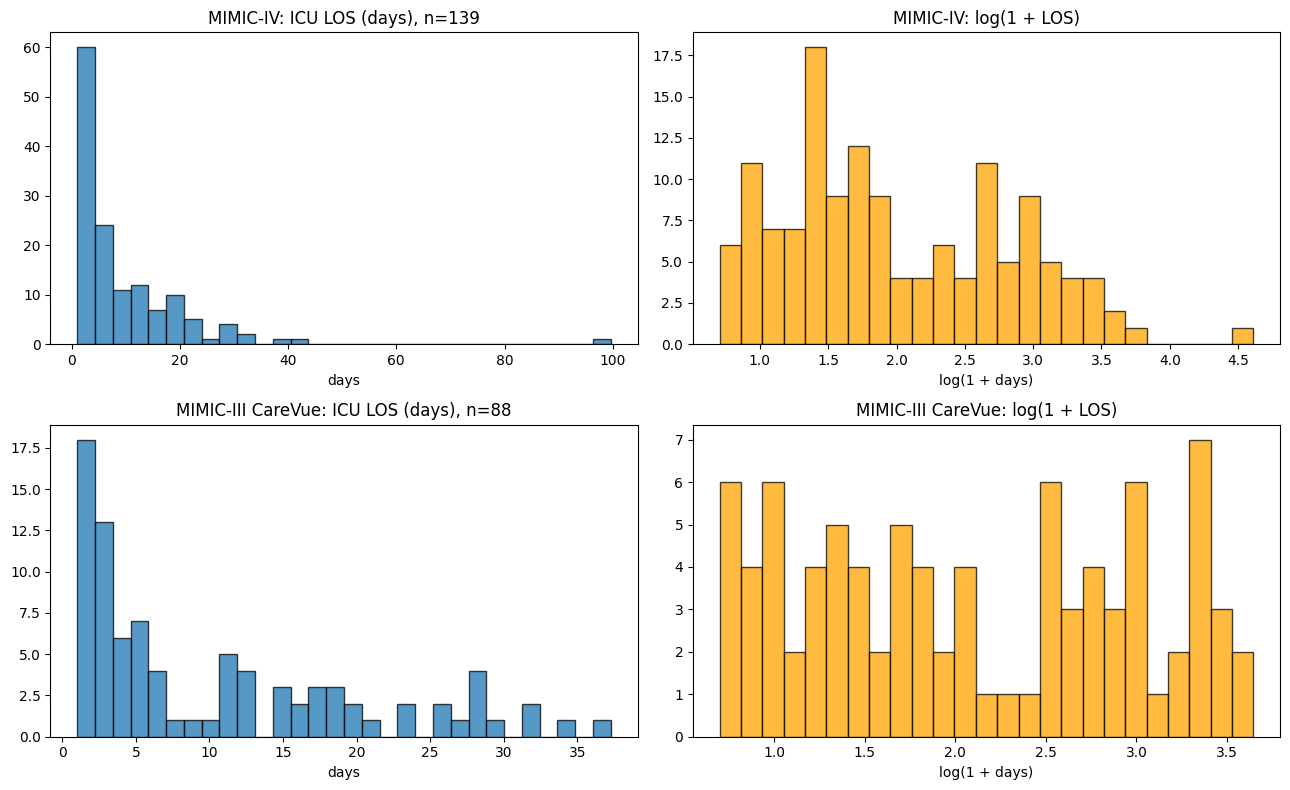


MIMIC-IV: strongest Spearman correlations with log LOS
mean_gcs_total     -0.364
max_gcs_total      -0.336
min_gcs_total      -0.327
min_po2            -0.173
mean_heart_rate    -0.165
mean_resp_rate      0.194
max_wbc             0.200
count_output_24h    0.238
count_input_24h     0.292
apache_ii           0.326

MIMIC-III CareVue: strongest Spearman correlations with log LOS
max_gcs_total     -0.552
mean_gcs_total    -0.507
min_gcs_total     -0.429
min_magnesium     -0.358
min_calcium       -0.354
max_chloride       0.303
apache_ii          0.401
mean_glucose       0.411
max_glucose        0.452
count_input_24h    0.452


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (name, f) in enumerate(PRIMARY_DATA.items()):
    title = name.split(' | ')[0]
    axes[row, 0].hist(f['los_days'], bins=30, edgecolor='black', alpha=0.75)
    axes[row, 0].set_title(f'{title}: ICU LOS (days), n={len(f)}')
    axes[row, 0].set_xlabel('days')
    axes[row, 1].hist(f['log_los'], bins=25, edgecolor='black', alpha=0.75, color='orange')
    axes[row, 1].set_title(f'{title}: log(1 + LOS)')
    axes[row, 1].set_xlabel('log(1 + days)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'los_distribution.png'), dpi=150)
plt.show()

for name, f in PRIMARY_DATA.items():
    num = f.select_dtypes(include=[np.number]).drop(columns=['stay_id', 'hadm_id', 'subject_id', 'los_days', 'log_los', 'hospital_expire_flag'], errors='ignore')
    corr = num.corrwith(f['log_los'], method='spearman').dropna().sort_values()
    print(f"\n{name.split(' | ')[0]}: strongest Spearman correlations with log LOS")
    print(pd.concat([corr.head(5), corr.tail(5)]).round(3).to_string())

## Step 7 — Modelling and evaluation

**Target:** `log(1 + LOS in days)`. Models are trained on the log scale; results are reported on the log scale **and** converted back to days (the scale used by published benchmarks).

**Models compared**
* *Median baseline* — predicts the training-fold median for everyone (the bar every model must clear).
* *APACHE-II (linear)* — `log LOS ~ APACHE-II approximation` (the brief's comparator, approximated).
* *APACHE-II no GCS (linear)* — the same, without GCS points (see the spinal-injury caveat in Step 1).
* *Lasso*, *Random Forest*, *XGBoost* — on the first-window features.

**Evaluation:** repeated, patient-grouped K-fold cross-validation. Every stay is predicted by a model that never saw that patient. Imputation and scaling are refit **inside each training fold** (they are pipeline steps). Confidence intervals come from a patient-level bootstrap. Model settings are fixed in advance; Lasso uses `alpha=0.01` and has no inner CV, avoiding an ungrouped patient-level tuning split.

### 7a. Choose the predictors
For each measurement we keep the mean plus the clinically "worst" extreme (min or max), to avoid near-duplicate min/mean/max trios.

In [18]:
WORST_IS_MIN = ['dbp', 'sbp', 'mbp', 'spo2', 'gcs_total', 'heart_rate', 'resp_rate', 'ph', 'po2', 'pco2', 'bicarbonate',
                'hematocrit', 'hemoglobin', 'platelets', 'sodium', 'potassium', 'chloride', 'calcium', 'magnesium']
WORST_IS_MAX = ['wbc', 'glucose', 'temp_c', 'lactate', 'creatinine', 'bun']
CAT_COLS = ['gender', 'admission_type']

Xd, yd, gd, num_d = {}, {}, {}, {}
for name, feat in DATA.items():
    num_cols = ['age', 'count_input_24h', 'count_output_24h']
    for var in WORST_IS_MIN + WORST_IS_MAX:
        worst = 'min' if var in WORST_IS_MIN else 'max'
        for pref in ('mean', worst):
            col = f'{pref}_{var}'
            if col in feat.columns and feat[col].notna().any():
                num_cols.append(col)
    bad = LEAKY & set(num_cols + CAT_COLS)
    assert not bad, f'leaky columns in feature list: {bad}'          # safety guard
    Xd[name] = feat[num_cols + CAT_COLS + ['apache_ii', 'apache_ii_no_gcs']].reset_index(drop=True)
    yd[name] = feat['log_los'].values
    gd[name] = feat['subject_id'].values
    num_d[name] = num_cols
    print(f'{name}: {len(feat)} stays, {len(np.unique(gd[name]))} patients, {len(num_cols)} numeric + {len(CAT_COLS)} categorical predictors')
print("\nNote: the columns named 'count_*_24h' hold the number of input/output entries inside each setting's own window.")

MIMIC-IV | Primary (24h window, min stay 24h): 139 stays, 138 patients, 53 numeric + 2 categorical predictors
MIMIC-III CareVue | Primary (24h window, min stay 24h): 88 stays, 88 patients, 53 numeric + 2 categorical predictors
MIMIC-IV | Keep short stays (24h window, no minimum stay): 156 stays, 155 patients, 53 numeric + 2 categorical predictors
MIMIC-III CareVue | Keep short stays (24h window, no minimum stay): 94 stays, 94 patients, 53 numeric + 2 categorical predictors
MIMIC-IV | Shorter window (12h window, min stay 12h): 148 stays, 147 patients, 53 numeric + 2 categorical predictors
MIMIC-III CareVue | Shorter window (12h window, min stay 12h): 92 stays, 92 patients, 53 numeric + 2 categorical predictors
MIMIC-IV | Longer window (48h window, min stay 48h): 117 stays, 116 patients, 53 numeric + 2 categorical predictors
MIMIC-III CareVue | Longer window (48h window, min stay 48h): 70 stays, 70 patients, 53 numeric + 2 categorical predictors
MIMIC-IV | Drop the 99-day stay (24h windo

### 7b. Define the models (as pipelines, so preprocessing is re-fit inside every training fold)

In [19]:
models_d = {}
for name in DATA:
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_d[name]),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT_COLS),
    ])
    models_d[name] = {
        'Median baseline': Pipeline([('prep', clone(prep)), ('m', DummyRegressor(strategy='median'))]),
        'APACHE-II (linear)': Pipeline([('sel', ColumnTransformer([('a', 'passthrough', ['apache_ii'])])),
                                        ('m', LinearRegression())]),
        'APACHE-II no GCS (linear)': Pipeline([('sel', ColumnTransformer([('a', 'passthrough', ['apache_ii_no_gcs'])])),
                                               ('m', LinearRegression())]),
        'Lasso': Pipeline([('prep', clone(prep)), ('m', Lasso(alpha=0.01, max_iter=200000))]),
        'RandomForest': Pipeline([('prep', clone(prep)),
                                  ('m', RandomForestRegressor(n_estimators=200, max_depth=6, min_samples_leaf=3,
                                                              random_state=RANDOM_STATE, n_jobs=-1))]),
        'XGBoost': Pipeline([('prep', clone(prep)),
                             ('m', XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                                                random_state=RANDOM_STATE, n_jobs=1, verbosity=0))]),
    }
print(list(models_d[PRIMARY_KEYS[0]]))

['Median baseline', 'APACHE-II (linear)', 'APACHE-II no GCS (linear)', 'Lasso', 'RandomForest', 'XGBoost']


### 7c. Patient-grouped, repeated cross-validation
Patients (not stays) are shuffled into folds, so a patient with two admissions is never split across training and validation. The whole procedure is repeated several times with different shuffles (10 for the primary analysis, fewer for the sensitivity settings to save time). The `assert` proves that no patient appears on both sides.

The reported primary pipeline uses `CLIP_PREDICTIONS = True`: each prediction is limited to the minimum and maximum LOS values seen in that training fold, for every model. This post-processing can reduce extreme extrapolation, but can also underpredict a genuine test stay longer than any training stay. Step 7e reports an uncapped comparison from the exact same fitted models and patient-grouped folds; clipping is a prediction-postprocessing sensitivity, not one of the five cohort/window settings.

In [20]:
oof_d = {}      # name -> model -> clipped out-of-fold predictions (repeats x stays)
oof_uncapped_d = {}  # same fitted fold models' predictions before training-range clipping
for name in DATA:
    X, y, groups = Xd[name], yd[name], gd[name]
    nrep = N_REPEATS if name.endswith(PRIMARY) else N_REPEATS_SENS
    uniq = np.unique(groups)
    rng = np.random.RandomState(RANDOM_STATE)
    oof = {m: np.full((nrep, len(y)), np.nan) for m in models_d[name]}
    oof_uncapped = {m: np.full((nrep, len(y)), np.nan) for m in models_d[name]}
    for r in range(nrep):
        perm = rng.permutation(uniq)
        fold_of = {g: i % N_SPLITS for i, g in enumerate(perm)}
        folds = np.array([fold_of[g] for g in groups])
        for k in range(N_SPLITS):
            tr, te = np.where(folds != k)[0], np.where(folds == k)[0]
            assert not (set(groups[tr]) & set(groups[te]))          # no patient on both sides
            for m, mdl in models_d[name].items():
                fitted = clone(mdl).fit(X.iloc[tr], y[tr])
                pred_uncapped = fitted.predict(X.iloc[te])
                oof_uncapped[m][r, te] = pred_uncapped
                pred_reported = pred_uncapped.copy()
                if CLIP_PREDICTIONS:
                    pred_reported = np.clip(pred_reported, y[tr].min(), y[tr].max())
                oof[m][r, te] = pred_reported
    oof_d[name] = oof
    oof_uncapped_d[name] = oof_uncapped
    print(f'{name}: CV finished ({nrep} repeats x {N_SPLITS} folds x {len(models_d[name])} models)')

MIMIC-IV | Primary (24h window, min stay 24h): CV finished (10 repeats x 5 folds x 6 models)
MIMIC-III CareVue | Primary (24h window, min stay 24h): CV finished (10 repeats x 5 folds x 6 models)
MIMIC-IV | Keep short stays (24h window, no minimum stay): CV finished (3 repeats x 5 folds x 6 models)
MIMIC-III CareVue | Keep short stays (24h window, no minimum stay): CV finished (3 repeats x 5 folds x 6 models)
MIMIC-IV | Shorter window (12h window, min stay 12h): CV finished (3 repeats x 5 folds x 6 models)
MIMIC-III CareVue | Shorter window (12h window, min stay 12h): CV finished (3 repeats x 5 folds x 6 models)
MIMIC-IV | Longer window (48h window, min stay 48h): CV finished (3 repeats x 5 folds x 6 models)
MIMIC-III CareVue | Longer window (48h window, min stay 48h): CV finished (3 repeats x 5 folds x 6 models)
MIMIC-IV | Drop the 99-day stay (24h window, min stay 24h): CV finished (3 repeats x 5 folds x 6 models)
MIMIC-III CareVue | Drop the 99-day stay (24h window, min stay 24h): CV

### 7d. Metrics (mean over repeats) and bootstrap confidence intervals
The bootstrap re-draws patients with replacement and re-scores every model on the **same** re-drawn patients, so differences between models are measured fairly (a paired comparison).

In [21]:
table_d = {}
for name in DATA:
    y = yd[name]
    rows = {}
    for m, arr in oof_d[name].items():
        recs = []
        for r in range(arr.shape[0]):
            p = np.clip(arr[r], 0, None)
            yday, pday = np.expm1(y), np.expm1(p)
            recs.append({'r2_log': r2_score(y, p), 'r2_days': r2_score(yday, pday),
                         'mae_days': mean_absolute_error(yday, pday),
                         'rmse_days': np.sqrt(mean_squared_error(yday, pday))})
        rec = pd.DataFrame(recs)
        rows[m] = {**{c: rec[c].mean() for c in rec}, **{f'{c}_sd': rec[c].std() for c in rec}}
    table_d[name] = pd.DataFrame(rows).T

boot_d, pred_d = {}, {}
for name in DATA:
    y, groups = yd[name], gd[name]
    nboot = N_BOOT if name.endswith(PRIMARY) else N_BOOT_SENS
    rng = np.random.RandomState(RANDOM_STATE)
    pred = {m: np.nanmean(arr, axis=0) for m, arr in oof_d[name].items()}
    idx_by_g = {g: np.where(groups == g)[0] for g in np.unique(groups)}
    ug = np.array(list(idx_by_g))
    boot = {m: {'r2_log': [], 'mae_days': []} for m in pred}
    for _ in range(nboot):
        s = np.concatenate([idx_by_g[g] for g in rng.choice(ug, size=len(ug), replace=True)])
        for m, p in pred.items():
            ps, ys = np.clip(p[s], 0, None), y[s]
            boot[m]['r2_log'].append(r2_score(ys, ps))
            boot[m]['mae_days'].append(mean_absolute_error(np.expm1(ys), np.expm1(ps)))
    boot_d[name] = {m: {k: np.array(v) for k, v in dd.items()} for m, dd in boot.items()}
    pred_d[name] = pred

    t = table_d[name]
    lo_hi = {m: (np.percentile(boot_d[name][m]['r2_log'], [2.5, 97.5]), np.percentile(boot_d[name][m]['mae_days'], [2.5, 97.5])) for m in t.index}
    t['r2_log_CI'] = [f'[{lo_hi[m][0][0]:.3f}, {lo_hi[m][0][1]:.3f}]' for m in t.index]
    t['mae_days_CI'] = [f'[{lo_hi[m][1][0]:.2f}, {lo_hi[m][1][1]:.2f}]' for m in t.index]

show_cols = ['r2_log', 'r2_log_sd', 'r2_log_CI', 'r2_days', 'mae_days', 'mae_days_CI', 'rmse_days']
for name in PRIMARY_KEYS:
    print(f'\n===== {name} =====')
    print(table_d[name][show_cols].round(3).to_string())


===== MIMIC-IV | Primary (24h window, min stay 24h) =====
                           r2_log  r2_log_sd         r2_log_CI  r2_days  mae_days   mae_days_CI  rmse_days
Median baseline            -0.061      0.010  [-0.164, -0.014]   -0.159     6.822  [5.29, 8.80]     12.376
APACHE-II (linear)          0.079      0.011   [-0.033, 0.164]   -0.015     6.654  [5.29, 8.39]     11.581
APACHE-II no GCS (linear)   0.001      0.016   [-0.073, 0.056]   -0.070     6.876  [5.47, 8.68]     11.894
Lasso                      -0.289      0.102   [-0.488, 0.031]   -0.045     7.326  [5.72, 8.61]     11.744
RandomForest                0.071      0.035   [-0.060, 0.196]    0.028     6.589  [5.22, 8.27]     11.336
XGBoost                     0.005      0.070   [-0.114, 0.208]    0.027     6.721  [5.22, 8.22]     11.338

===== MIMIC-III CareVue | Primary (24h window, min stay 24h) =====
                           r2_log  r2_log_sd         r2_log_CI  r2_days  mae_days   mae_days_CI  rmse_days
Median baseline  

### 7e. Prediction clipping sensitivity (same folds, same fitted predictions)
The main model table uses fold-specific training-range clipping because `CLIP_PREDICTIONS = True`. Here we compare those predictions with the *uncapped* predictions from the exact same fitted models and patient-grouped folds. Both versions retain the nonnegative LOS floor used when scoring log predictions; "uncapped" means no training-range minimum/maximum cap. Patient-level bootstrap resampling is paired, so each capped/uncapped difference uses the same sampled patients. This is separate from the five cohort/window sensitivity settings.

In [22]:
clipping_rows = []
for name in DATA:
    y = yd[name]
    patient_groups = gd[name]
    clipped_predictions = {model_name: np.nanmean(prediction_array, axis=0)
                           for model_name, prediction_array in oof_d[name].items()}
    uncapped_predictions = {model_name: np.nanmean(prediction_array, axis=0)
                             for model_name, prediction_array in oof_uncapped_d[name].items()}

    # Recreate the same patient bootstrap draws used for the main paired model comparisons.
    rng = np.random.RandomState(RANDOM_STATE)
    patient_indices = {patient_id: np.where(patient_groups == patient_id)[0]
                       for patient_id in np.unique(patient_groups)}
    unique_patients = np.array(list(patient_indices))
    bootstrap_differences = {model_name: {'delta_r2_log': [], 'delta_r2_days': []}
                             for model_name in clipped_predictions}
    n_bootstrap = N_BOOT if name.endswith(PRIMARY) else N_BOOT_SENS

    for bootstrap_number in range(n_bootstrap):
        sampled_indices = np.concatenate([
            patient_indices[patient_id]
            for patient_id in rng.choice(unique_patients, size=len(unique_patients), replace=True)
        ])
        sampled_actual_log_los = y[sampled_indices]
        sampled_actual_days = np.expm1(sampled_actual_log_los)

        for model_name in clipped_predictions:
            sampled_clipped_log_prediction = np.clip(clipped_predictions[model_name][sampled_indices], 0, None)
            sampled_uncapped_log_prediction = np.clip(uncapped_predictions[model_name][sampled_indices], 0, None)
            clipped_r2_log = r2_score(sampled_actual_log_los, sampled_clipped_log_prediction)
            uncapped_r2_log = r2_score(sampled_actual_log_los, sampled_uncapped_log_prediction)
            clipped_r2_days = r2_score(sampled_actual_days, np.expm1(sampled_clipped_log_prediction))
            uncapped_r2_days = r2_score(sampled_actual_days, np.expm1(sampled_uncapped_log_prediction))
            bootstrap_differences[model_name]['delta_r2_log'].append(uncapped_r2_log - clipped_r2_log)
            bootstrap_differences[model_name]['delta_r2_days'].append(uncapped_r2_days - clipped_r2_days)

    for model_name in clipped_predictions:
        uncapped_repeat_metrics = []
        for repeat_number in range(oof_uncapped_d[name][model_name].shape[0]):
            raw_prediction = np.clip(oof_uncapped_d[name][model_name][repeat_number], 0, None)
            actual_days = np.expm1(y)
            predicted_days = np.expm1(raw_prediction)
            uncapped_repeat_metrics.append({
                'r2_log': r2_score(y, raw_prediction),
                'r2_days': r2_score(actual_days, predicted_days),
            })
        uncapped_metrics = pd.DataFrame(uncapped_repeat_metrics).mean()
        clipped_metrics = table_d[name].loc[model_name]
        log_delta_samples = np.asarray(bootstrap_differences[model_name]['delta_r2_log'])
        days_delta_samples = np.asarray(bootstrap_differences[model_name]['delta_r2_days'])
        log_delta_ci = np.percentile(log_delta_samples, [2.5, 97.5])
        days_delta_ci = np.percentile(days_delta_samples, [2.5, 97.5])
        clipping_rows.append({
            'dataset_setting': name,
            'model': model_name,
            'clipped_r2_log': clipped_metrics['r2_log'],
            'uncapped_r2_log': uncapped_metrics['r2_log'],
            'uncapped_minus_clipped_r2_log': uncapped_metrics['r2_log'] - clipped_metrics['r2_log'],
            'paired_delta_r2_log_95pct_CI': f'[{log_delta_ci[0]:.3f}, {log_delta_ci[1]:.3f}]',
            'clipped_r2_days': clipped_metrics['r2_days'],
            'uncapped_r2_days': uncapped_metrics['r2_days'],
            'uncapped_minus_clipped_r2_days': uncapped_metrics['r2_days'] - clipped_metrics['r2_days'],
            'paired_delta_r2_days_95pct_CI': f'[{days_delta_ci[0]:.3f}, {days_delta_ci[1]:.3f}]',
        })
clipping_sensitivity = pd.DataFrame(clipping_rows)
clipping_sensitivity.to_csv(os.path.join(OUT_DIR, 'clipping_sensitivity.csv'), index=False)
primary_clipping_rows = clipping_sensitivity[clipping_sensitivity['dataset_setting'].str.endswith(PRIMARY)]
print('Primary-setting comparison: uncapped minus clipped performance (paired patient bootstrap)\n')
print(primary_clipping_rows[['dataset_setting', 'model', 'clipped_r2_log', 'uncapped_r2_log',
                            'paired_delta_r2_log_95pct_CI', 'clipped_r2_days', 'uncapped_r2_days',
                            'paired_delta_r2_days_95pct_CI']].round(3).to_string(index=False))
print(f'\nSaved paired clipping sensitivity results for {len(clipping_sensitivity)} dataset-setting/model combinations.')

Primary-setting comparison: uncapped minus clipped performance (paired patient bootstrap)

                                       dataset_setting                     model  clipped_r2_log  uncapped_r2_log paired_delta_r2_log_95pct_CI  clipped_r2_days  uncapped_r2_days paired_delta_r2_days_95pct_CI
         MIMIC-IV | Primary (24h window, min stay 24h)           Median baseline          -0.061           -0.061               [0.000, 0.000]           -0.159            -0.159                [0.000, 0.000]
         MIMIC-IV | Primary (24h window, min stay 24h)        APACHE-II (linear)           0.079            0.079               [0.000, 0.000]           -0.015            -0.015                [0.000, 0.000]
         MIMIC-IV | Primary (24h window, min stay 24h) APACHE-II no GCS (linear)           0.001            0.001               [0.000, 0.000]           -0.070            -0.070                [0.000, 0.000]
         MIMIC-IV | Primary (24h window, min stay 24h)                     La

### How to read the tables
* `r2_log` / `r2_days`: mean over repeated grouped CV (out-of-fold). `r2_log_sd` is the spread across repeats. `*_CI` is a 95% patient-level bootstrap interval. **If the intervals of two models overlap heavily, the data cannot tell them apart.**
* An R² below zero means the model does worse than predicting the average.
* Published benchmarks (Verburg et al., 2017; R² 0.05–0.28) are on LOS in days, so compare them with `r2_days`, not `r2_log`.
* The next cell answers the two questions that matter: does the best model beat the median baseline, and does it beat the APACHE-II approximation?

In [23]:
best_d = {}
for name in DATA:
    ml = ['Lasso', 'RandomForest', 'XGBoost']
    best_d[name] = max(ml, key=lambda m: table_d[name].loc[m, 'r2_log'])

for name in PRIMARY_KEYS:
    best = best_d[name]
    print(f"\n{name}: best ML model by mean out-of-fold R2(log) = {best}  (picking the best of 3 after looking is mildly optimistic)")
    for ref in ['Median baseline', 'APACHE-II (linear)', 'APACHE-II no GCS (linear)']:
        diff = boot_d[name][best]['r2_log'] - boot_d[name][ref]['r2_log']
        lo, hi = np.percentile(diff, [2.5, 97.5])
        verdict = 'better' if lo > 0 else 'worse' if hi < 0 else 'NOT distinguishable'
        print(f'  {best} minus {ref:26s}: delta R2(log) = {diff.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  -> {verdict}')


MIMIC-IV | Primary (24h window, min stay 24h): best ML model by mean out-of-fold R2(log) = RandomForest  (picking the best of 3 after looking is mildly optimistic)
  RandomForest minus Median baseline           : delta R2(log) = +0.148  95% CI [-0.027, +0.294]  -> NOT distinguishable
  RandomForest minus APACHE-II (linear)        : delta R2(log) = +0.009  95% CI [-0.105, +0.115]  -> NOT distinguishable
  RandomForest minus APACHE-II no GCS (linear) : delta R2(log) = +0.086  95% CI [-0.045, +0.211]  -> NOT distinguishable

MIMIC-III CareVue | Primary (24h window, min stay 24h): best ML model by mean out-of-fold R2(log) = RandomForest  (picking the best of 3 after looking is mildly optimistic)
  RandomForest minus Median baseline           : delta R2(log) = +0.275  95% CI [+0.119, +0.440]  -> better
  RandomForest minus APACHE-II (linear)        : delta R2(log) = +0.078  95% CI [-0.077, +0.239]  -> NOT distinguishable
  RandomForest minus APACHE-II no GCS (linear) : delta R2(log) = +0.1

### Figures (primary analysis): model comparison, predicted vs actual, APACHE vs LOS, importance

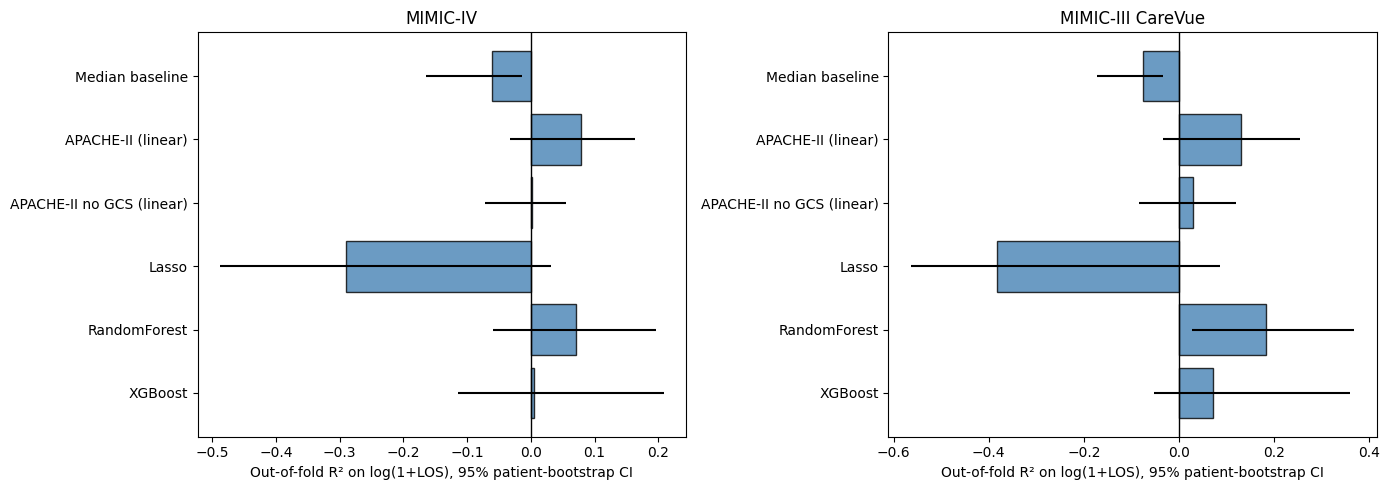

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, PRIMARY_KEYS):
    t = table_d[name]
    cis = {m: np.percentile(boot_d[name][m]['r2_log'], [2.5, 97.5]) for m in t.index}
    lo = [t.loc[m, 'r2_log'] - cis[m][0] for m in t.index]
    hi = [cis[m][1] - t.loc[m, 'r2_log'] for m in t.index]
    ax.barh(t.index, t['r2_log'], xerr=[lo, hi], color='steelblue', edgecolor='black', alpha=0.8)
    ax.axvline(0, color='k', lw=1)
    ax.set_xlabel('Out-of-fold R² on log(1+LOS), 95% patient-bootstrap CI')
    ax.set_title(name.split(' | ')[0])
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'model_comparison.png'), dpi=150)
plt.show()

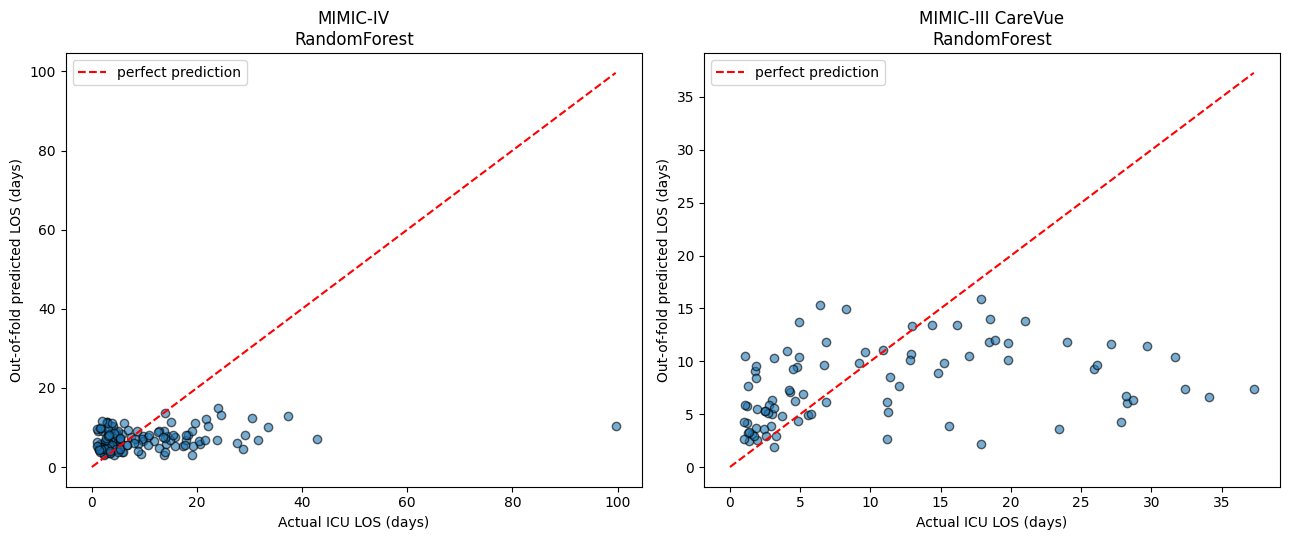

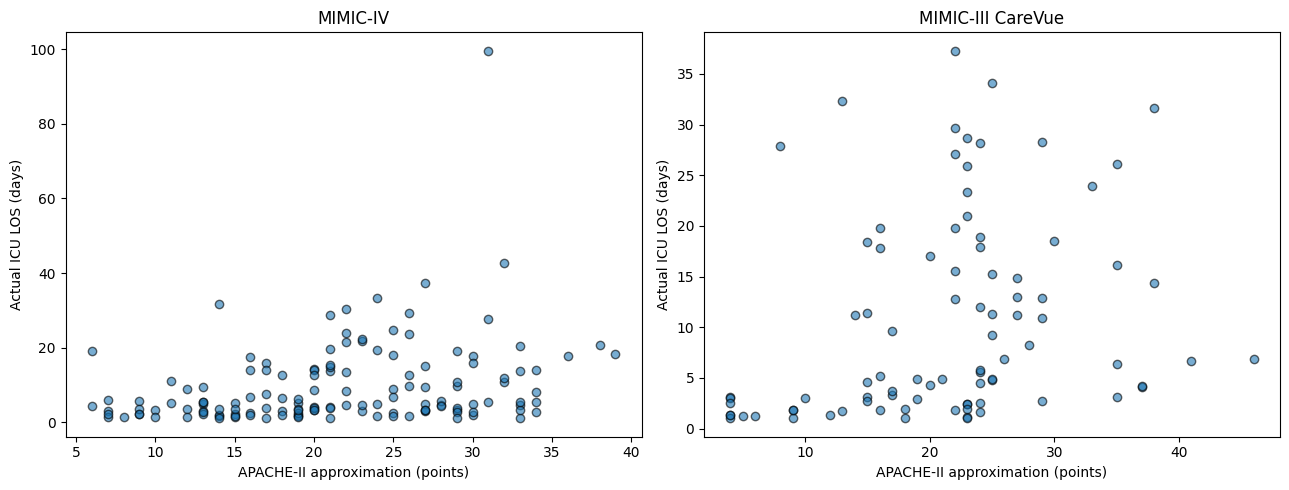

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, PRIMARY_KEYS):
    best = best_d[name]
    p_days = np.expm1(np.clip(pred_d[name][best], 0, None))
    a_days = np.expm1(yd[name])
    ax.scatter(a_days, p_days, alpha=0.6, edgecolor='black')
    top = max(a_days.max(), p_days.max())
    ax.plot([0, top], [0, top], 'r--', label='perfect prediction')
    ax.set_xlabel('Actual ICU LOS (days)')
    ax.set_ylabel('Out-of-fold predicted LOS (days)')
    ax.set_title(f"{name.split(' | ')[0]}\n{best}")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'actual_vs_predicted.png'), dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, f) in zip(axes, PRIMARY_DATA.items()):
    ax.scatter(f['apache_ii'], f['los_days'], alpha=0.6, edgecolor='black')
    ax.set_xlabel('APACHE-II approximation (points)')
    ax.set_ylabel('Actual ICU LOS (days)')
    ax.set_title(name.split(' | ')[0])
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'apache_vs_los.png'), dpi=150)
plt.show()


MIMIC-IV — top 10 permutation importances (rise in held-out MAE, log scale, when the feature is shuffled):
mean_gcs_total      0.0517
count_input_24h     0.0070
mean_resp_rate      0.0045
mean_glucose        0.0036
min_gcs_total       0.0021
count_output_24h    0.0018
mean_temp_c         0.0013
min_calcium         0.0012
mean_spo2           0.0011
mean_platelets      0.0009

MIMIC-III CareVue — top 10 permutation importances (rise in held-out MAE, log scale, when the feature is shuffled):
mean_gcs_total     0.0383
max_glucose        0.0376
count_input_24h    0.0320
mean_glucose       0.0175
mean_ph            0.0087
mean_temp_c        0.0074
min_gcs_total      0.0068
min_magnesium      0.0054
min_po2            0.0042
mean_creatinine    0.0037


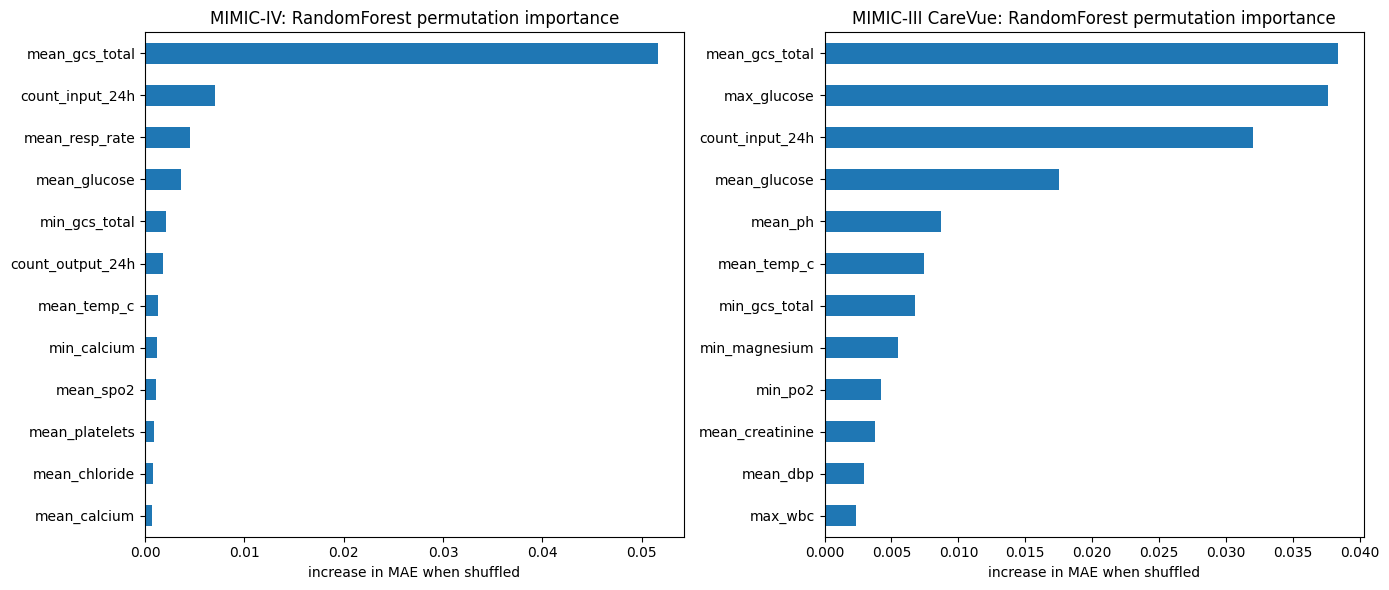

In [26]:
# Permutation importance on HELD-OUT folds (first CV repeat) for the Random Forest, averaged over folds.
# It shuffles the raw columns, so feature names are always correct. Treat it as hypothesis-generating only.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, PRIMARY_KEYS):
    X, y, groups = Xd[name], yd[name], gd[name]
    cols = num_d[name] + CAT_COLS
    uniq = np.unique(groups)
    perm = np.random.RandomState(RANDOM_STATE).permutation(uniq)
    fold_of = {g: i % N_SPLITS for i, g in enumerate(perm)}
    folds = np.array([fold_of[g] for g in groups])
    imps = []
    for k in range(N_SPLITS):
        tr, te = np.where(folds != k)[0], np.where(folds == k)[0]
        fitted = clone(models_d[name]['RandomForest']).fit(X.iloc[tr], y[tr])
        pi = permutation_importance(fitted, X.iloc[te], y[te], n_repeats=10, random_state=RANDOM_STATE,
                                    scoring='neg_mean_absolute_error')
        imps.append(pd.Series(pi.importances_mean, index=X.columns)[cols])
    imp = pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False)
    print(f"\n{name.split(' | ')[0]} — top 10 permutation importances (rise in held-out MAE, log scale, when the feature is shuffled):")
    print(imp.head(10).round(4).to_string())
    imp.head(12).sort_values().plot(kind='barh', ax=ax)
    ax.set_title(f"{name.split(' | ')[0]}: RandomForest permutation importance")
    ax.set_xlabel('increase in MAE when shuffled')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'feature_importance.png'), dpi=150)
plt.show()

## Step 8 — Results summary (primary analysis)

In [ ]:
summary = pd.concat({name.split(' | ')[0]: table_d[name][['r2_log', 'r2_log_CI', 'r2_days', 'mae_days', 'mae_days_CI']].round(3)
                     for name in PRIMARY_KEYS})
print(summary.to_string())
summary.to_csv(os.path.join(OUT_DIR, 'results_summary.csv'))
for name, f in PRIMARY_DATA.items():
    print(f"\n{name.split(' | ')[0]}: LOS median {f['los_days'].median():.1f} d, mean {f['los_days'].mean():.1f} d, SD {f['los_days'].std():.1f} d "
          f"-> an RMSE close to that SD means the model adds little over the mean")  

                                             r2_log         r2_log_CI  r2_days  mae_days   mae_days_CI
MIMIC-IV          Median baseline            -0.061  [-0.164, -0.014]   -0.159     6.822  [5.29, 8.80]
                  APACHE-II (linear)          0.079   [-0.033, 0.164]   -0.015     6.654  [5.29, 8.39]
                  APACHE-II no GCS (linear)   0.001   [-0.073, 0.056]   -0.070     6.876  [5.47, 8.68]
                  Lasso                      -0.289   [-0.488, 0.031]   -0.045     7.326  [5.72, 8.61]
                  RandomForest                0.071   [-0.060, 0.196]    0.028     6.589  [5.22, 8.27]
                  XGBoost                     0.005   [-0.114, 0.208]    0.027     6.721  [5.22, 8.22]
MIMIC-III CareVue Median baseline            -0.075  [-0.173, -0.034]   -0.246     7.972  [6.43, 9.44]
                  APACHE-II (linear)          0.131   [-0.034, 0.254]   -0.093     7.420  [6.00, 8.83]
                  APACHE-II no GCS (linear)   0.029   [-0.084, 0.119]   -

## Step 9 — Sensitivity: do our choices change the conclusions?
Every setting from Step 0 was analysed automatically from the same extracted data, using identical code. Each row below is one full analysis, so the settings can be compared directly (nothing here was run by hand).

* **Keep short stays:** what happens if stays under 24h are *not* removed?
* **Shorter / longer window:** do 12 or 48 hours of data change the picture?
* **Drop the 99-day stay:** is one extreme patient driving the results?

The sensitivity settings use fewer CV repeats and bootstrap draws than the primary analysis, so their intervals are a little rougher.

In [28]:
tidy = pd.concat({name: table_d[name][['r2_log', 'r2_days', 'mae_days']] for name in DATA}, names=['key', 'model']).reset_index()
tidy['dataset'] = tidy['key'].str.split(' | ', regex=False).str[0]
tidy['setting'] = tidy['key'].str.split(' | ', regex=False).str[1]
tidy['n_stays'] = tidy['key'].map({k: len(yd[k]) for k in DATA})

pivot = tidy.pivot_table(index=['dataset', 'model'], columns='setting', values='r2_log')[list(SETTINGS)].round(3)
pivot.columns = [c.split(' (')[0] for c in pivot.columns]
print('Out-of-fold R2 on log(1+LOS) for every model and setting:\n')
print(pivot.to_string())

rows = []
for name in DATA:
    best = best_d[name]
    line = {'dataset': name.split(' | ')[0], 'setting': name.split(' | ')[1].split(' (')[0], 'n_stays': len(yd[name]),
            'best_ML': best, 'best_r2_log': round(table_d[name].loc[best, 'r2_log'], 3),
            'best_r2_days': round(table_d[name].loc[best, 'r2_days'], 3)}
    for ref, col in [('Median baseline', 'vs_median'), ('APACHE-II (linear)', 'vs_APACHE_II')]:
        diff = boot_d[name][best]['r2_log'] - boot_d[name][ref]['r2_log']
        lo, hi = np.percentile(diff, [2.5, 97.5])
        line[col] = 'better' if lo > 0 else 'worse' if hi < 0 else 'not distinguishable'
    if name.endswith('Keep short stays (24h window, no minimum stay)'):
        line['vs_median'] = 'not comparable: stay may end before 24h'
        line['vs_APACHE_II'] = 'not comparable: stay may end before 24h'
    rows.append(line)
sens = pd.DataFrame(rows)
print('\nBest ML model in each setting, and whether it clearly beats the two baselines (95% paired bootstrap):\n')
print(sens.to_string(index=False))
sens.to_csv(os.path.join(OUT_DIR, 'sensitivity_summary.csv'), index=False)
tidy.to_csv(os.path.join(OUT_DIR, 'results_all_settings.csv'), index=False)

Out-of-fold R2 on log(1+LOS) for every model and setting:

                                             Primary  Keep short stays  Shorter window  Longer window  Drop the 99-day stay
dataset           model                                                                                                    
MIMIC-III CareVue APACHE-II (linear)           0.131             0.102           0.083          0.034                 0.122
                  APACHE-II no GCS (linear)    0.029            -0.010           0.001         -0.013                 0.011
                  Lasso                       -0.383            -0.386          -0.317         -0.887                -0.398
                  Median baseline             -0.075            -0.078          -0.050         -0.045                -0.052
                  RandomForest                 0.183             0.253           0.184          0.085                 0.228
                  XGBoost                      0.073             0.203   

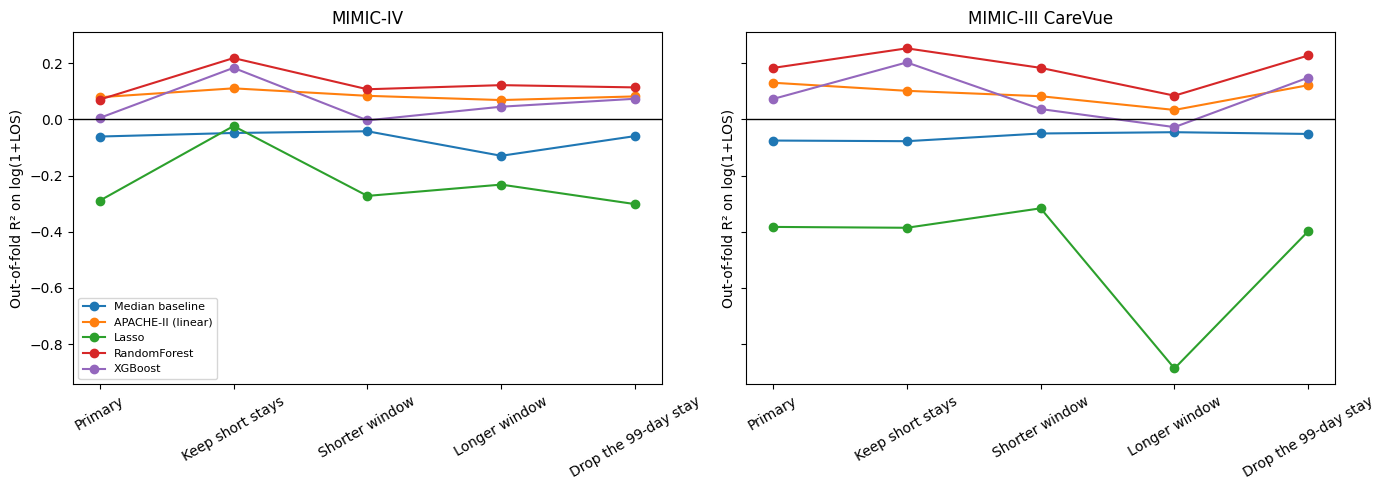

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
short = [s.split(' (')[0] for s in SETTINGS]
for ax, dname in zip(axes, INPUTS):
    for m in ['Median baseline', 'APACHE-II (linear)', 'Lasso', 'RandomForest', 'XGBoost']:
        vals = [table_d[f'{dname} | {s}'].loc[m, 'r2_log'] for s in SETTINGS]
        ax.plot(short, vals, marker='o', label=m)
    ax.axhline(0, color='k', lw=1)
    ax.set_title(dname)
    ax.set_ylabel('Out-of-fold R² on log(1+LOS)')
    ax.tick_params(axis='x', rotation=30)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'sensitivity.png'), dpi=150)
plt.show()

## Step 10 — Assumptions, limitations and what to conclude

### Assumptions we made (and where they were tested)
| Choice | What it assumes | Tested? |
|---|---|---|
| 24-hour window | Day-1 data are enough, and day 1 is the right moment to predict | Yes — 12h and 48h windows (Step 9) |
| Excluding stays shorter than the window | Prediction happens at the end of the window, so the target group is patients still in the ICU | Yes — "keep short stays" (Step 9) |
| One extreme 99-day stay kept | It is a real patient, not a data error | Yes — "drop the 99-day stay" (Step 9) |
| `log(1 + LOS)` target | Proportional errors matter more than absolute ones | Reported on both log and day scales |
| First ICU stay per admission | Later stays are readmissions with a different clinical meaning | No |
| Median imputation | Missing labs are roughly typical | No (lactate and blood gases are ordered selectively, so this is a real simplification) |
| Arterial-only blood gases | Venous samples would misstate oxygenation | No |
| Diagnosis codes ICD-9 `806.0x` and ICD-10 `S14.1xxA` | These codes define an acute cervical cord injury | No |
| Training-range prediction clipping (`CLIP_PREDICTIONS=True`) | Capping every model's predictions at the training-fold LOS minimum and maximum limits extrapolation | Yes — paired capped/uncapped evaluation on identical folds (Step 7e) |
| Lasso penalty (`alpha=0.01`) | A fixed penalty avoids an inner tuning split that would not group patients | No — fixed in advance, not cross-validated |
| Other fixed model settings | Small data do not support heavy tuning | No |

### Limitations (read these before interpreting any number)
* **Very small sample** (roughly 90–140 stays per dataset). Every estimate is noisy; rely on the confidence intervals, not the point estimates.
* **The comparator is APACHE-II, not APACHE-IV.** APACHE-IV's method and predictors are published, but faithful reproduction requires its diagnosis-category mapping and model details; the fields available here do not provide those inputs in a directly usable form. Our APACHE-II score is an approximation built from MIMIC variables, and it is a general severity score, not a length-of-stay model.
* **Chronic-health points and the cohort itself use diagnosis codes assigned at discharge.** A bedside tool would not know them at hour 24.
* **Early death shortens a stay**, so LOS mixes "recovered quickly" with "died quickly". Deaths are counted but not modelled separately.
* **GCS is hard to interpret in spinal cord injury**: ventilated patients are charted verbal = 1, so a low GCS may mean "intubated" rather than "brain injury".
* **Two datasets, one hospital, different eras and charting systems.** Differences between the MIMIC-IV and MIMIC-III results reflect time and charting practice, not different hospitals. Some features (for example input-event counts) are not comparable across the two systems. The datasets cannot be checked for overlapping patients, so they are never pooled.
* **No spinal-injury-specific variables** (neurological level, ASIA grade, ventilation, timing of surgery). These probably matter more than generic physiology.
* **MIMIC-IV v2.2 excludes a held-out group of patients**, so this cohort comes from a subset of the hospital's true spinal-injury population.
* **Choosing the best of three models after seeing the results** is mildly optimistic; the paired intervals partly account for this.

### Key takeaways
In the primary MIMIC-IV cohort (139 stays), Random Forest achieved `R²=0.071` on log(1+LOS) and `R²=0.028` on LOS in days. Its paired improvement over the median baseline on the log scale was not distinguishable from zero (ΔR²=0.148, 95% CI −0.027 to 0.294), nor was its difference from the APACHE-II approximation (ΔR²=0.009, 95% CI −0.105 to 0.115). APACHE-II itself had log-scale `R²=0.079` and day-scale `R²=−0.015`. Thus, this analysis does **not** establish that the first-day model predicts LOS better than either comparator in the primary dataset.
In the separate MIMIC-III CareVue primary analysis (88 stays), Random Forest achieved log-scale `R²=0.183` but day-scale `R²=0.009`; it was distinguishable from the median baseline but not from APACHE-II. Treat this as a secondary replication within the same hospital, not independent external validation. The paired clipping check shows that clipping leaves the Random Forest primary results unchanged to three decimals in both datasets. It does materially affect Lasso in CareVue: uncapped log-scale R² is −0.669 versus −0.383 clipped, and uncapped day-scale R² is −26.240 versus −0.549 clipped (paired log-scale ΔR² 95% CI −0.674 to −0.051). Lasso remains a poor model either way; the cap prevents severe extrapolation but does not rescue its performance. Random Forest had the highest mean log-scale R² among the machine-learning models across the five settings, but the size of its apparent advantage varied. The keep-short-stays result is **not comparable** as a complete 24-hour prediction test because those stays can end before the feature window is observed. Overall, these small cohorts provide weak and uncertain LOS prediction; the result should not be framed as beating APACHE-II. The feature-importance plot is hypothesis-generating, not causal evidence.